# 📊 Exploratory Data Analysis — Customer Messy Data (`01_eda_customers.ipynb`)

**Author:** Levi Flores (`@levifvy`)  
**Dataset:** [Kaggle — Customer Messy Data (`ruchikakumbhar1806/customer-messy-data`)](https://www.kaggle.com/datasets/ruchikakumbhar1806/customer-messy-data)  
**Scope:** Essential Level (`E1–E6`: Load, Diagnose, Clean, Univariate & Bivariate Analysis, and Business Question Synthesis) + Medium Level Block 1 (`M1–M4`: Cleaning Rationale, Outlier Treatment, Segment Aggregations, and Feature Engineering)

---

## 1. `[E1]` Load and Inspect the Dataset

### 1.1 Business Context & Guiding Research Questions
The company has collected **10,000 customer records** across multiple cities and international markets, capturing demographic attributes (`Name`, `Gender`, `Age`, `City`, `Country`), acquisition and engagement timestamps (`Signup_Date`, `Last_purchase_date`), commercial value (`purchase_amount`), customer satisfaction (`feedback_score`), and contact channels (`email`, `Phone_number`). However, upstream ingestion defects have introduced blank entries, sentinel values (`-999`, `-1`, `-5`, `200`, `0`), malformed strings (`not_a_date`, `missing`, `N/A`, `abc123`), and inconsistent categorical casing.

Before conducting statistical modeling or executive reporting, this Exploratory Data Analysis addresses **three core business questions**:

1. **Q1 — Customer Demographics & Geographic Footprint:** *What is the true demographic and geographic profile (`age`, `gender`, `city`, `country`) of our active customer base once sentinel values and formatting inconsistencies are resolved, and are there structural mismatches between reported city and country?*
2. **Q2 — Revenue Distribution & High-Value Segments:** *How is `purchase_amount` distributed across demographic groups (`gender`, `age` brackets) and locations (`city` / `country`), and which customer segments drive the highest average transaction value?*
3. **Q3 — Customer Satisfaction, Retention & Channel Reachability:** *How does customer satisfaction (`feedback_score`) relate to purchase spending and customer tenure (`signup_date` to `last_purchase_date`), and what proportion of customers have valid, reachable contact information (`email`, `phone_number`) for retention campaigns?*


In [1]:
import os
import warnings

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RAW_PATH = os.path.join("..", "data", "raw", "messy_customer_data.csv")
PROCESSED_PATH = os.path.join("..", "data", "processed", "customers_clean_v1.csv")

# Load the raw dataset without automatic NA coercion first to inspect literal strings
df_raw = pd.read_csv(RAW_PATH, keep_default_na=False)
print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print("\nColumn names:", list(df_raw.columns))


Dataset shape: 10,000 rows × 12 columns

Column names: ['CustomerID', 'Name', 'Gender', 'Age', 'City', 'Signup_Date', 'Last_purchase_date', 'purchase_amount', 'feedback_score', 'email', 'Phone_number', 'Country']


### 1.2 Initial Inspection: `head()`, `info()`, and `describe()`
We inspect the first 10 rows, schema information (`info()`), and descriptive summary statistics (`describe()`) both on raw string representations and with default `pandas` `NaN` parsing.

In [2]:
print("=== FIRST 10 ROWS (RAW) ===")
print(df_raw.head(10).to_string())

print("\n=== SCHEMA & DATA TYPES (with default pandas NA parsing) ===")
df_default = pd.read_csv(RAW_PATH)
df_default.info()

print("\n=== SUMMARY STATISTICS (NUMERIC COLUMNS BEFORE CLEANING) ===")
print(df_default.describe().round(2).to_string())

print("\n=== SUMMARY STATISTICS (OBJECT / CATEGORICAL COLUMNS BEFORE CLEANING) ===")
print(df_default.describe(include="object").to_string())


=== FIRST 10 ROWS (RAW) ===
  CustomerID    Name  Gender  Age       City Signup_Date Last_purchase_date purchase_amount feedback_score           email Phone_number    Country
0              Ankit       F   36     Mumbai  31/12/2024         13/08/2025            -999              2                            0     Canada
1         C2    Ravi  Female         Kolkata                                            N/A             -1   user1mail.com       abc123     Canada
2          3    Ravi  female   66  Ahmedabad                     20/06/2023             N/A             10  user2@mail.com       abc123      India
3         C4   Ankit    male   44    Kolkata                     13/09/2025                                                  9316267914        USA
4          5   Rahul    Male  200  Ahmedabad  09/07/2025                               -999                  user4mail.com   9234603292        USA
5         C6    Amit           64     Mumbai  not_a_date                                N/

---

## 2. `[E2]` Diagnose Data Quality

A rigorous audit of `messy_customer_data.csv` reveals that **standard `df.isnull().sum()` only captures blank cells (`""`) and `"N/A"`, missing thousands of domain-specific sentinel values and corrupted placeholders** embedded across columns:

- **Implicit missing / placeholder strings:** `"not_a_date"`, `"missing"`, `"N/A"`, `"abc123"`, `"0"`.
- **Numeric sentinel & impossible values:**
  - `Age`: `-5` (negative age, 2,506 rows) and `200` (impossible human age, 2,453 rows).
  - `purchase_amount`: `-999` (sentinel code for missing amount, 2,501 rows).
  - `feedback_score`: `-1` (sentinel code for unrated/missing feedback, 2,489 rows) and `10` (2,521 rows outside the standard `1–5` rating scale, requiring explicit flagging).
- **Malformed contact strings:** `email` entries missing the `@` symbol (e.g., `user1mail.com`).
- **Temporal & geographic anomalies:** rows where `Last_purchase_date < Signup_Date`, and Indian cities (`Mumbai`, `Delhi`, `Bangalore`, etc.) paired with non-Indian country labels (`USA`, `UK`, `Canada`, `Australia`).

In [3]:
def diagnose_column_quality(df):
    total = len(df)
    records = []

    invalid_rules = {
        "CustomerID": lambda s: s.isin([""]),
        "Name": lambda s: s.isin([""]),
        "Gender": lambda s: s.isin([""]),
        "Age": lambda s: s.isin(["", "-5", "200"]),
        "City": lambda s: s.isin([""]),
        "Signup_Date": lambda s: s.isin(["", "not_a_date"]),
        "Last_purchase_date": lambda s: s.isin(["", "missing"]),
        "purchase_amount": lambda s: s.isin(["", "N/A", "-999"]),
        "feedback_score": lambda s: s.isin(["", "-1"]),
        "email": lambda s: (s == "") | (~s.str.contains("@", regex=False)),
        "Phone_number": lambda s: s.isin(["", "abc123", "0"]),
        "Country": lambda s: s.isin([""]),
    }

    for col in df.columns:
        s = df[col].astype(str).str.strip()
        blank_cnt = int((s == "").sum())
        invalid_mask = invalid_rules[col](s)
        total_invalid = int(invalid_mask.sum())
        sentinel_cnt = total_invalid - blank_cnt
        valid_cnt = total - total_invalid
        records.append({
            "Column": col,
            "Raw Dtype": str(df_default[col].dtype),
            "Blank ('')": blank_cnt,
            "Sentinel / Corrupted": sentinel_cnt,
            "Total Invalid / Missing": total_invalid,
            "Invalid (%)": round(total_invalid / total * 100, 2),
            "Valid Count": valid_cnt,
            "Valid (%)": round(valid_cnt / total * 100, 2),
        })

    return pd.DataFrame(records)

quality_df = diagnose_column_quality(df_raw)
print("=== DATA QUALITY DIAGNOSIS PER COLUMN (10,000 ROWS) ===")
print(quality_df.to_string(index=False))

print("\n=== DUPLICATE CHECK ===")
print(f"Exact full-row duplicates: {df_raw.duplicated().sum()}")
non_empty_ids = df_raw.loc[df_raw["CustomerID"] != "", "CustomerID"].str.replace("C", "", regex=False)
print(f"Duplicate non-empty numeric CustomerIDs: {non_empty_ids.duplicated().sum()}")


=== DATA QUALITY DIAGNOSIS PER COLUMN (10,000 ROWS) ===
            Column Raw Dtype  Blank ('')  Sentinel / Corrupted  Total Invalid / Missing  Invalid (%)  Valid Count  Valid (%)
        CustomerID       str        2379                     0                     2379        23.79         7621      76.21
              Name       str        1658                     0                     1658        16.58         8342      83.42
            Gender       str        2455                     0                     2455        24.55         7545      75.45
               Age   float64        2576                  4959                     7535        75.35         2465      24.65
              City       str        1130                     0                     1130        11.30         8870      88.70
       Signup_Date       str        2529                  2475                     5004        50.04         4996      49.96
Last_purchase_date       str        3286                  3366       

### 2.1 Cleaning-Decision Table (`E2`)

| Original Column | Cleaned Column (`snake_case`) | Target Type | Identified Defects (`n` / `%`) | Cleaning & Imputation Decision |
|---|---|---|---|---|
| `CustomerID` | `customer_id` | `string` (`C00001`–`C10000`) | `2,379` blanks (`23.79%`); mixed `'C2'` vs `'3'` format | Reconstruct sequential ID `C00001`–`C10000` from row position (verified 1-to-1 match with existing IDs). |
| `Name` | `name` | `string` | `1,658` blanks (`16.58%`) | Strip whitespace, title-case, and impute missing values as `'Unknown'`. |
| `Gender` | `gender` | `category` (`Male`, `Female`, `Unknown`) | `2,455` blanks (`24.55%`); 6 casing variants (`M`, `male`, `Male`, `F`, `female`, `Female`) | Map `M`/`male`/`Male` → `'Male'`, `F`/`female`/`Female` → `'Female'`, and blanks → `'Unknown'`. |
| `Age` | `age` | `float64` (nullable numeric) | `2,576` blanks (`25.76%`), `2,506` equal to `-5`, `2,453` equal to `200` (`75.35%` invalid total) | Replace `-5` and `200` with `NaN`. Keep `NaN` in `age` to avoid distorting distribution variance, and provide `age_imputed` (median) + `is_age_missing` flag. |
| `City` | `city` | `category` | `1,130` blanks (`11.30%`) | Standardise title case and impute missing values as `'Unknown'`. |
| `Signup_Date` | `signup_date` | `datetime64[ns]` | `2,529` blanks (`25.29%`) + `2,475` `'not_a_date'` (`50.04%` invalid) | Parse `DD/MM/YYYY` with `errors='coerce'` (`NaT` for invalid/missing). |
| `Last_purchase_date` | `last_purchase_date` | `datetime64[ns]` | `3,286` blanks (`32.86%`) + `3,366` `'missing'` (`66.52%` invalid) | Parse `DD/MM/YYYY` with `errors='coerce'`. Flag chronological inversions (`last_purchase_date < signup_date`). |
| `purchase_amount` | `purchase_amount` | `float64` | `2,500` blanks + `2,533` `'N/A'` + `2,501` `'-999'` (`75.34%` invalid) | Replace `'N/A'` and `-999` with `NaN`; cast to `float64`. Keep `NaN` for accurate spend analytics and create `purchase_amount_imputed` (median) + `is_purchase_missing` flag. |
| `feedback_score` | `feedback_score` | `float64` | `2,462` blanks + `2,489` `'-1'` (`49.51%` invalid); `2,521` rows have score `10` | Replace `-1` and blanks with `NaN` (valid scores `1–5` and `10`). Also create normalised `feedback_score_1_to_5` (where `10` is rescaled/flagged) for sensitivity checks. |
| `email` | `email` | `string` | `5,066` blanks (`50.66%`) + `2,487` malformed strings without `@` (`75.53%` invalid) | Retain valid emails matching `user@domain`; set malformed/blank entries to `NaN` and add boolean `has_valid_email`. |
| `Phone_number` | `phone_number` | `string` | `2,444` blanks + `2,586` `'abc123'` + `2,460` `'0'` (`74.90%` invalid) | Retain valid 10-digit phone numbers; set placeholders (`abc123`, `0`, blank) to `NaN` and add boolean `has_valid_phone`. |
| `Country` | `country` | `category` | `1,704` blanks (`17.04%`) | Standardise strings and impute missing values as `'Unknown'`. |


---

## 3. `[E3]` Fix Data Types, Standardise Columns and Export Clean Dataset v1

We now execute the deterministic cleaning pipeline in accordance with the table above:
1. Rename all 12 columns to `snake_case`.
2. Reconstruct sequential `customer_id` (`C00001`–`C10000`) and verify zero ID collisions.
3. Standardise categorical fields (`name`, `gender`, `city`, `country`).
4. Replace numeric sentinels (`-5`, `200`, `-999`, `-1`, `N/A`) with `np.nan` and cast to `float64`.
5. Parse `signup_date` and `last_purchase_date` as `datetime64[ns]` (`dayfirst=True`).
6. Validate `email` and `phone_number` formats and add reachability/quality flags.
7. Export the cleaned dataset to `data/processed/customers_clean_v1.csv`.

In [4]:
df_clean = df_raw.copy()

# 1. Rename columns to snake_case
column_mapping = {
    "CustomerID": "customer_id",
    "Name": "name",
    "Gender": "gender",
    "Age": "age",
    "City": "city",
    "Signup_Date": "signup_date",
    "Last_purchase_date": "last_purchase_date",
    "purchase_amount": "purchase_amount",
    "feedback_score": "feedback_score",
    "email": "email",
    "Phone_number": "phone_number",
    "Country": "country",
}
df_clean = df_clean.rename(columns=column_mapping)

# 2. Reconstruct standardised customer_id (C00001 .. C10000)
df_clean["customer_id"] = [f"C{i:05d}" for i in range(1, len(df_clean) + 1)]

# 3. Clean text & categorical columns
df_clean["name"] = df_clean["name"].str.strip().str.title().replace({"": "Unknown"})

gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "": "Unknown",
}
df_clean["gender"] = df_clean["gender"].str.strip().str.lower().map(gender_map).fillna("Unknown")

df_clean["city"] = df_clean["city"].str.strip().str.title().replace({"": "Unknown"})
df_clean["country"] = df_clean["country"].str.strip().replace({"": "Unknown"})

# 4. Clean numeric columns and replace sentinel values with NaN
age_num = pd.to_numeric(df_clean["age"], errors="coerce")
df_clean["age"] = age_num.where((age_num >= 18) & (age_num <= 100), np.nan)

amt_num = pd.to_numeric(df_clean["purchase_amount"].replace({"N/A": np.nan, "-999": np.nan, "": np.nan}), errors="coerce")
df_clean["purchase_amount"] = amt_num.where(amt_num > 0, np.nan)

fb_num = pd.to_numeric(df_clean["feedback_score"].replace({"-1": np.nan, "": np.nan}), errors="coerce")
df_clean["feedback_score"] = fb_num.where(fb_num >= 1, np.nan)

# 5. Parse dates (DD/MM/YYYY)
df_clean["signup_date"] = pd.to_datetime(
    df_clean["signup_date"].replace({"not_a_date": np.nan, "": np.nan}),
    format="%d/%m/%Y",
    errors="coerce",
)
df_clean["last_purchase_date"] = pd.to_datetime(
    df_clean["last_purchase_date"].replace({"missing": np.nan, "": np.nan}),
    format="%d/%m/%Y",
    errors="coerce",
)

# 6. Validate email and phone_number
email_str = df_clean["email"].str.strip()
df_clean["email"] = email_str.where(email_str.str.contains(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", regex=True), np.nan)

phone_str = df_clean["phone_number"].str.strip()
df_clean["phone_number"] = phone_str.where(phone_str.str.match(r"^\d{10}$"), np.nan)

# Add auxiliary quality & reachability indicators for downstream analysis
df_clean["has_valid_email"] = df_clean["email"].notna()
df_clean["has_valid_phone"] = df_clean["phone_number"].notna()
df_clean["is_date_inverted"] = (
    df_clean["signup_date"].notna()
    & df_clean["last_purchase_date"].notna()
    & (df_clean["last_purchase_date"] < df_clean["signup_date"])
)

# Cast categorical columns for memory and analytical efficiency
for cat_col in ["gender", "city", "country"]:
    df_clean[cat_col] = df_clean[cat_col].astype("category")

# Export clean dataset v1
os.makedirs(os.path.dirname(PROCESSED_PATH), exist_ok=True)
df_clean.to_csv(PROCESSED_PATH, index=False)
print(f"Saved cleaned dataset to: {PROCESSED_PATH}")
print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns\n")
df_clean.info()


Saved cleaned dataset to: ..\data\processed\customers_clean_v1.csv
Cleaned dataset shape: 10,000 rows × 15 columns

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         10000 non-null  str           
 1   name                10000 non-null  str           
 2   gender              10000 non-null  category      
 3   age                 2465 non-null   float64       
 4   city                10000 non-null  category      
 5   signup_date         4996 non-null   datetime64[us]
 6   last_purchase_date  3348 non-null   datetime64[us]
 7   purchase_amount     2466 non-null   float64       
 8   feedback_score      5049 non-null   float64       
 9   email               2512 non-null   str           
 10  phone_number        2510 non-null   str           
 11  country             10000 non-null  category      
 12

In [5]:
print("=== CLEANED DATASET HEAD(10) ===")
print(df_clean.head(10).to_string())

print("\n=== SUMMARY STATISTICS AFTER CLEANING (NUMERIC) ===")
print(df_clean[["age", "purchase_amount", "feedback_score"]].describe().round(2).to_string())

print("\n=== STANDARDISED CATEGORICAL COUNTS ===")
for col in ["gender", "city", "country"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False).to_string())

print("\n=== CONTACT & TEMPORAL QUALITY SUMMARY ===")
print(f"Valid emails: {df_clean['has_valid_email'].sum():,} ({df_clean['has_valid_email'].mean()*100:.2f}%)")
print(f"Valid 10-digit phones: {df_clean['has_valid_phone'].sum():,} ({df_clean['has_valid_phone'].mean()*100:.2f}%)")
print(f"Both dates present: {(df_clean['signup_date'].notna() & df_clean['last_purchase_date'].notna()).sum():,}")
print(f"Inverted dates (last_purchase_date < signup_date): {df_clean['is_date_inverted'].sum():,}")


=== CLEANED DATASET HEAD(10) ===
  customer_id    name   gender   age       city signup_date last_purchase_date  purchase_amount  feedback_score           email phone_number    country  has_valid_email  has_valid_phone  is_date_inverted
0      C00001   Ankit   Female  36.0     Mumbai  2024-12-31         2025-08-13              NaN             2.0             NaN          NaN     Canada            False            False             False
1      C00002    Ravi   Female   NaN    Kolkata         NaT                NaT              NaN             NaN             NaN          NaN     Canada            False            False             False
2      C00003    Ravi   Female  66.0  Ahmedabad         NaT         2023-06-20              NaN            10.0  user2@mail.com          NaN      India             True            False             False
3      C00004   Ankit     Male  44.0    Kolkata         NaT         2025-09-13              NaN             NaN             NaN   9316267914        USA

---

## 4. `[E4]` Univariate Analysis

### 4.1 Quantitative Univariate Profiling (Parametric & Non-Parametric)

Before constructing visual distributions, we compute both **parametric** (`mean`, `SD`) and **non-parametric** (`median`, `Q1`, `Q3`, `IQR`, `min`, `max`, `skewness`, `kurtosis`) univariate statistics across all valid numeric observations, alongside total and known-record frequency shares across categorical and reachability dimensions (`src/analysis.py`).

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.analysis import (
    compute_bivariate_segment_spend,
    compute_city_country_crosstab,
    compute_research_question_kpis,
    compute_univariate_categorical_counts,
    compute_univariate_numeric_stats,
    load_clean_customers,
    run_bivariate_hypothesis_tests,
)
from src.visualization import (
    plot_e4_age_distribution,
    plot_e4_demographics_counts,
    plot_e4_feedback_and_reachability,
    plot_e4_purchase_distribution,
    plot_e5_age_vs_spend,
    plot_e5_feedback_and_geo_mismatch,
    plot_e5_spend_by_city_and_age,
    plot_e5_spend_by_demographics,
)

df_v1 = load_clean_customers("v1")
e4_num_stats = compute_univariate_numeric_stats(df_v1)
e4_cat_counts = compute_univariate_categorical_counts(df_v1)

print("=== [E4] UNIVARIATE NUMERIC STATISTICS (PARAMETRIC & NON-PARAMETRIC) ===")
print(e4_num_stats.round(2).to_string(index=False))

print("\n=== [E4] UNIVARIATE CATEGORICAL & REACHABILITY COUNTS ===")
print(e4_cat_counts.round(2).to_string(index=False))

=== [E4] UNIVARIATE NUMERIC STATISTICS (PARAMETRIC & NON-PARAMETRIC) ===
             variable  n_total  n_valid  n_missing  coverage_pct    mean     std   min      q1  median      q3     max    iqr  skewness  kurtosis
                  age    10000     2465       7535         24.65   43.70   15.30 18.00   31.00   43.00   58.00   70.00   27.0      0.06     -1.19
      purchase_amount    10000     2466       7534         24.66 2450.62 1442.83 10.31 1159.38 2460.36 3733.88 4998.67 2574.5      0.01     -1.22
       feedback_score    10000     5049       4951         50.49    6.48    3.66  1.00    3.00    5.00   10.00   10.00    7.0     -0.21     -1.71
feedback_score_1_to_5    10000     2528       7472         25.28    2.96    1.42  1.00    2.00    3.00    4.00    5.00    2.0      0.06     -1.29
          tenure_days    10000      855       9145          8.55  688.59  464.11  0.00  299.50  638.00 1010.00 1925.00  710.5      0.52     -0.60

=== [E4] UNIVARIATE CATEGORICAL & REACHABILITY COU

**Quantitative Interpretation (`E4`):**
- **Demographics (`Q1`):** Valid `age` covers **24.65%** of accounts ($n = 2,465$ of $10,000$; $7,535$ missing/sentinel remediated to `NaN`). Both parametric (`mean = 43.70` years, `SD = 15.30` years) and non-parametric (`median = 43.00` years, `IQR = 27.00` years, `Q1 = 31.00`, `Q3 = 58.00`, `range = 18.00–70.00`) metrics align closely, with near-zero skewness (`0.0602`) and negative excess kurtosis (`-1.1894`) characteristic of a flat, near-uniform age distribution. Known `gender` ($n = 7,545$, `75.45%` coverage) is balanced between `Male` ($n = 3,800$, `50.36%` of known) and `Female` ($n = 3,745$, `49.64%` of known). Known `city` ($n = 8,870$) is evenly split across 8 Indian cities (`11.91%` in `Kolkata` to `12.90%` in `Hyderabad`), while known `country` ($n = 8,296$) is evenly split (~`20%` each) across `USA`, `Australia`, `Canada`, `UK`, and `India`.
- **Transaction Spend (`Q2`):** Valid `purchase_amount` ($n = 2,466$, `24.66%` coverage) exhibits symmetric, platykurtic dispersion across `$10.31–$4,998.67`: `mean = $2,450.62` (`SD = $1,442.83`) and `median = $2,460.36` (`IQR = $2,574.50`, `Q1 = $1,159.39`, `Q3 = $3,733.88`, `skewness = 0.0139`, `kurtosis = -1.2150`), yielding `$6,043,218.46` in total verified spend.
- **Satisfaction, Lifecycle Tenure & Reachability (`Q3`):** Raw valid `feedback_score` ($n = 5,049$, `50.49%` coverage) has `mean = 6.48` (`median = 5.00`, `IQR = 7.00`) solely because an off-scale spike at `10` accounts for **49.93%** of all valid ratings ($n = 2,521$). Restricting to the standard Likert scale (`feedback_score_1_to_5`, $n = 2,528$) reveals a neutral central tendency (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`). Chronologically valid `tenure_days` ($n = 855$ accounts where `last_purchase_date >= signup_date`) shows mild right skewness (`0.5179`), with `mean = 688.59` days (`SD = 464.11`) vs. `median = 638.00` days (`IQR = 710.50`, range `0–1,925` days). Across all $10,000$ accounts, **56.12%** ($n = 5,612$) are `Unreachable (None)`, leaving **43.88%** ($n = 4,388$) reachable via `Email Only` (`18.78%`), `Phone Only` (`18.76%`), or `Omnichannel (Both)` (`6.34%`).

### 4.2 Univariate Visual Profiling — Continuous, Categorical & Reachability Distributions

Each visualization pairs parametric (`mean`, `SD`) and non-parametric (`median`, `Q1`, `Q3`, `IQR`, Tukey fences) markers directly on the canvas and exports deterministically at `300 DPI` to `assets/charts/` via `src/visualization.py`.

Saved figure: assets/charts/e4_univariate_age_distribution.png


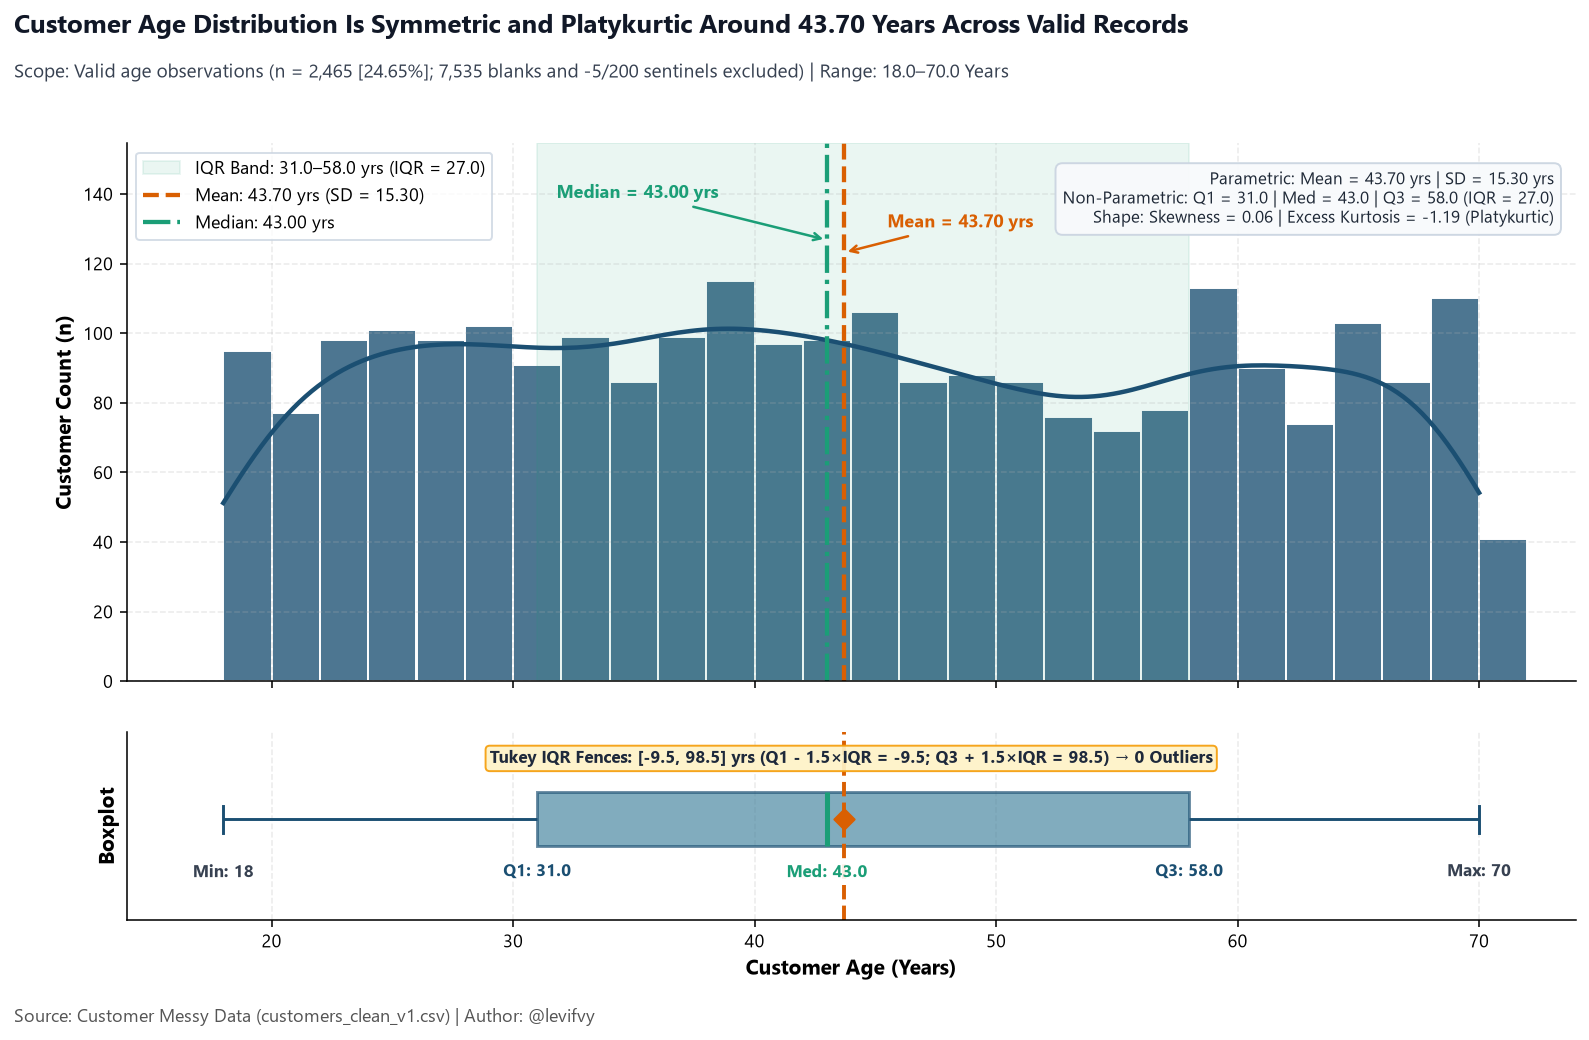

In [7]:
fig_e4_age = plot_e4_age_distribution(df_v1, save=True)
plt.show()
plt.close(fig_e4_age)

**Visual Interpretation — Customer Age Distribution (`Q1` Demographics):**
- Across valid observations ($n = 2,465$, **24.65%** coverage; $7,535$ blank or `-5`/`200` sentinel records excluded to `NaN` rather than single-value median imputation, which would artificially compress `SD` from `15.30` to `~7.6` years), `age` spans **18.0 to 70.0 years** smoothly.
- Parametric (`mean = 43.70` years, `SD = 15.30` years) and non-parametric (`median = 43.00` years, `Q1 = 31.0`, `Q3 = 58.0`, `IQR = 27.0` years) central tendencies converge tightly, with near-zero skewness (`0.06`) and negative excess kurtosis (`-1.19`) confirming a symmetric, platykurtic (near-uniform) adult age profile.
- Formal Tukey fences ($[-9.5,\; 98.5]$ years) lie well outside the observed `[18.0, 70.0]` support, confirming **0 univariate age outliers** after sentinel removal.

Saved figure: assets/charts/e4_univariate_purchase_distribution.png


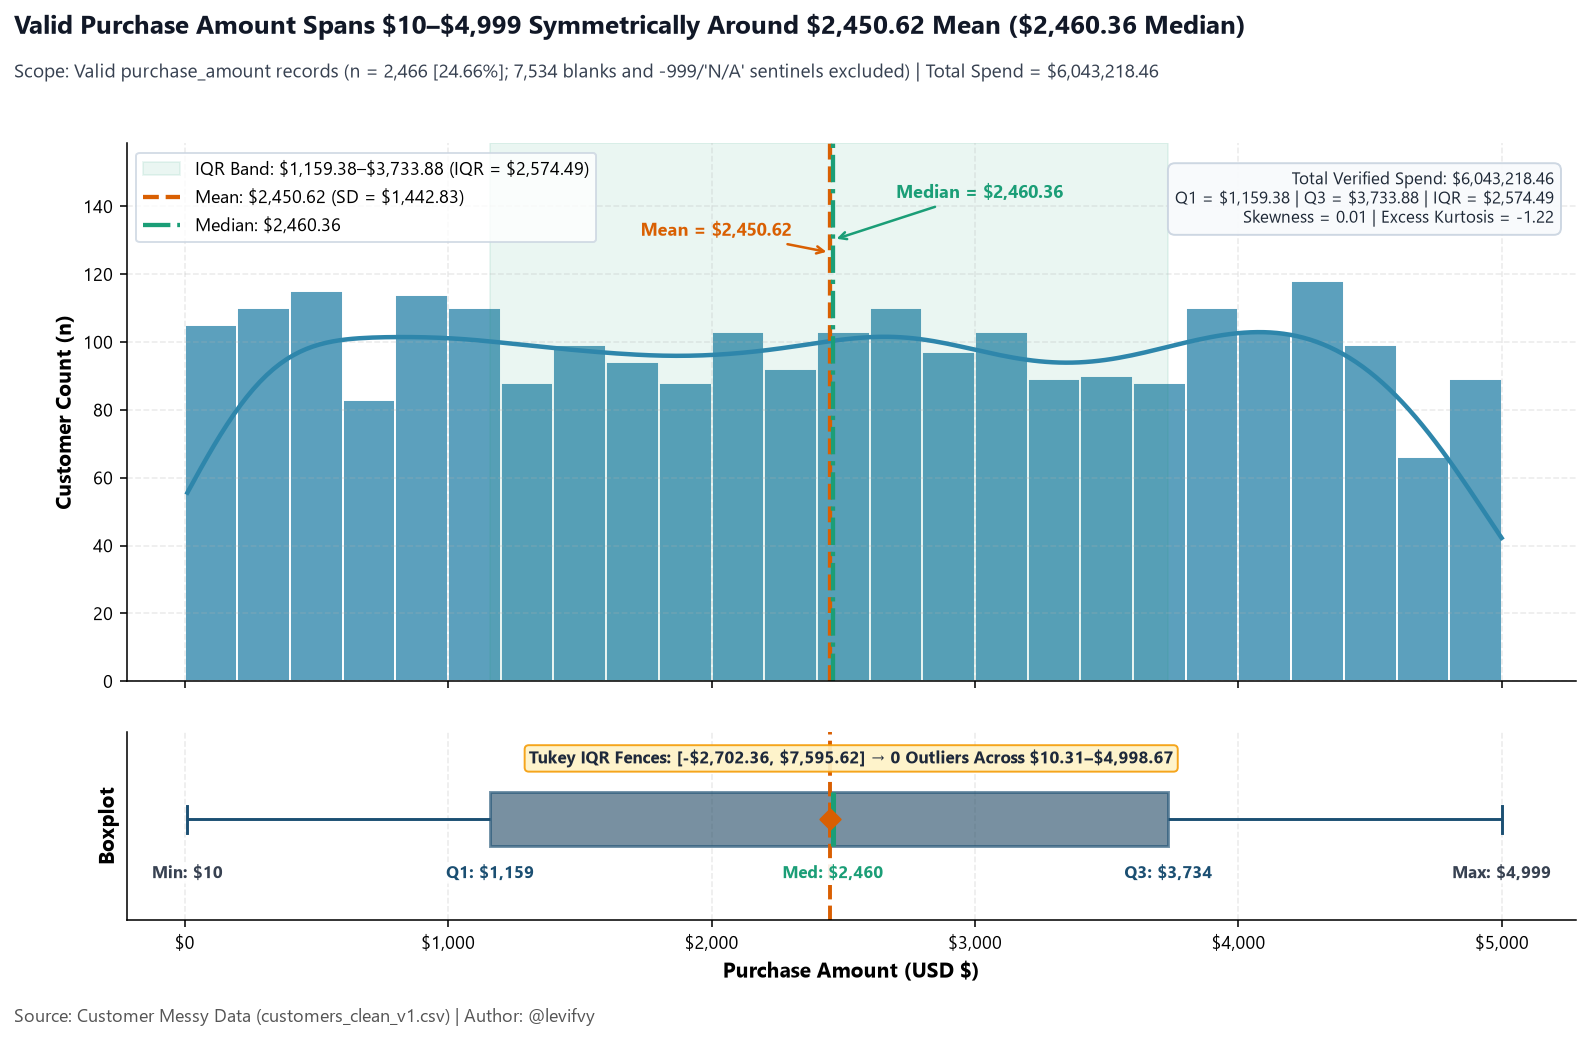

In [8]:
fig_e4_spend = plot_e4_purchase_distribution(df_v1, save=True)
plt.show()
plt.close(fig_e4_spend)

**Visual Interpretation — Transaction Spend Distribution (`Q2` Revenue Distribution):**
- Valid `purchase_amount` covers **24.66%** of accounts ($n = 2,466$; $7,534$ blanks and `-999`/`'N/A'` sentinels excluded), generating **$6,043,218.46** in verified transaction volume across `$10.31–$4,998.67`.
- Both `mean` (**$2,450.62**, `SD = $1,442.83`) and `median` (**$2,460.36**, `Q1 = $1,159.39`, `Q3 = $3,733.88`, `IQR = $2,574.50`) sit virtually at the midpoint of the `$0–$5,000` range (`skewness = 0.01`, excess `kurtosis = -1.22`), demonstrating uniform dispersion across low, mid, and high ticket sizes.
- Formal Tukey fences ($[-\$2,702.36,\; \$7,595.62]$) confirm **0 statistical spend outliers** among valid transactions, meaning top-tier orders (`>$3,500`) represent genuine broad-spectrum demand rather than isolated extreme anomalies.

Saved figure: assets/charts/e4_univariate_demographics_counts.png


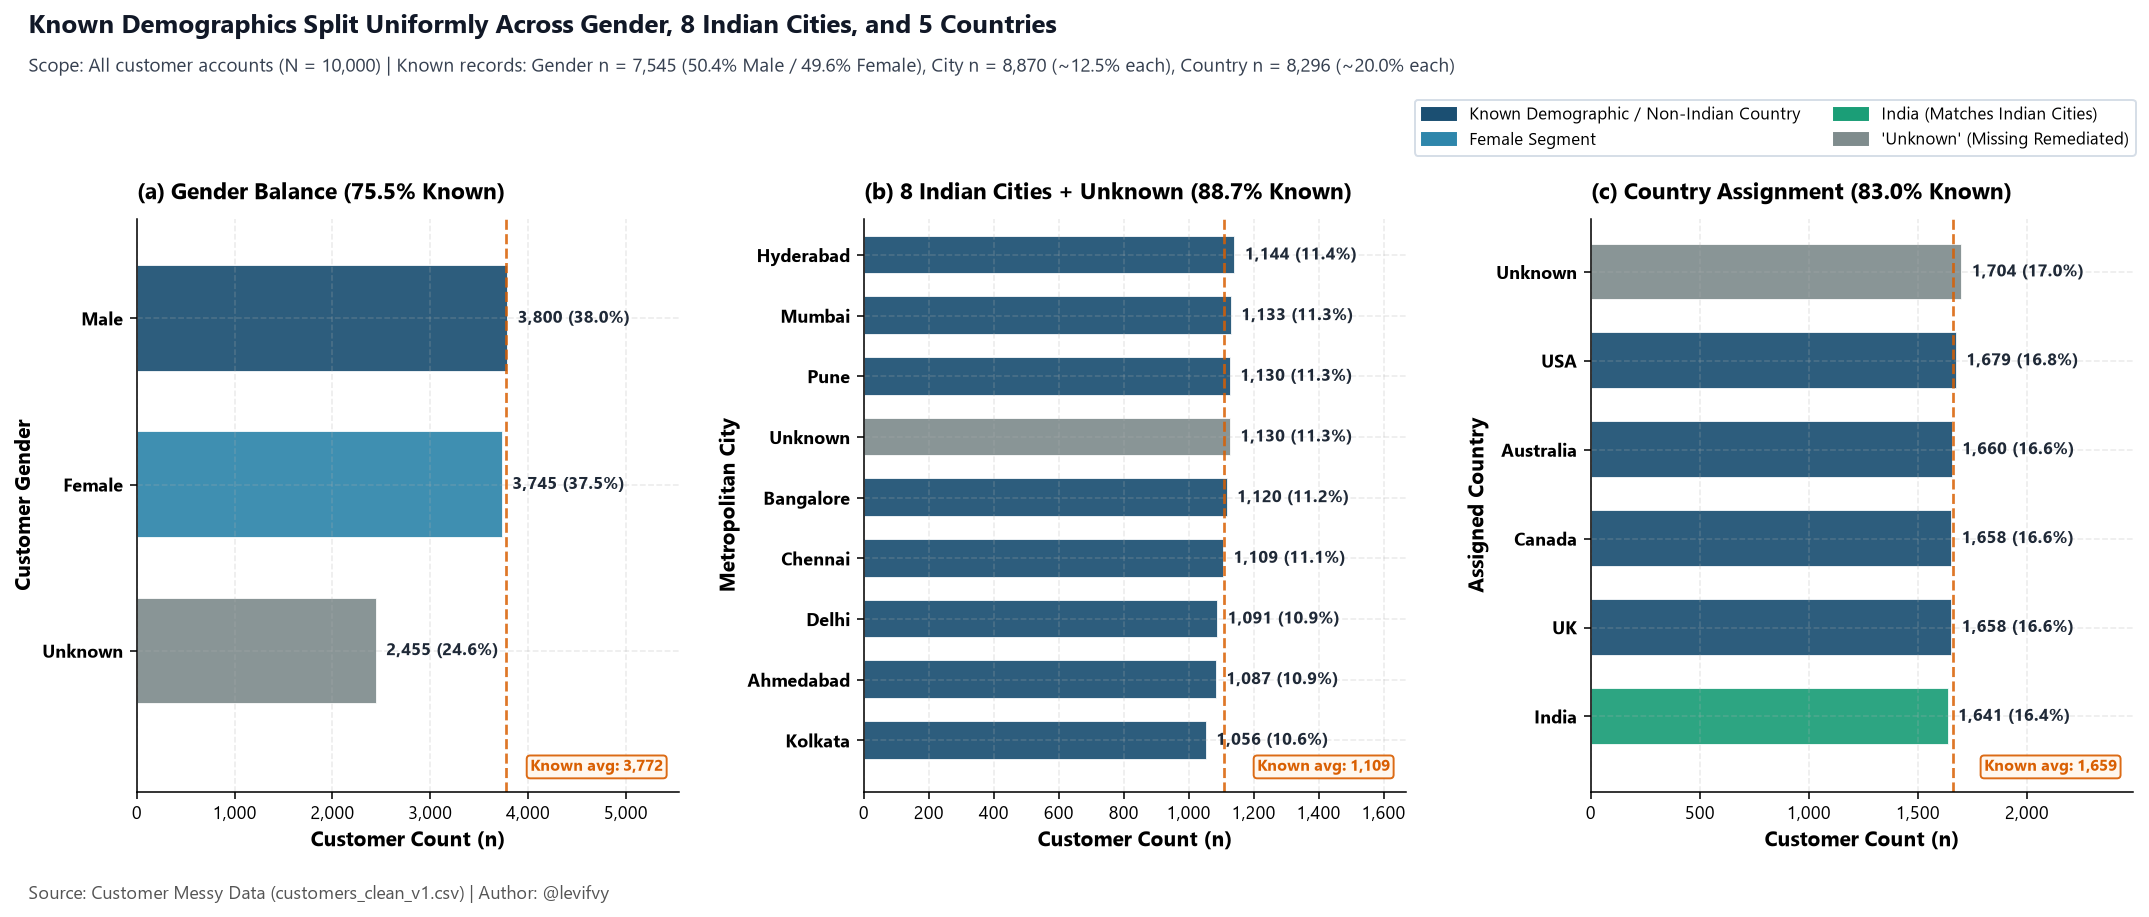

In [9]:
fig_e4_demo = plot_e4_demographics_counts(df_v1, save=True)
plt.show()
plt.close(fig_e4_demo)

**Visual Interpretation — Demographic & Geographic Counts (`Q1` Customer Profile):**
- **Gender (`75.45%` known, $n = 7,545$):** Nearly 50/50 parity between `Male` ($n = 3,800$, `38.0%` total / `50.36%` known) and `Female` ($n = 3,745$, `37.5%` total / `49.64%` known), alongside `2,455` (`24.6%`) `'Unknown'` accounts rendered in slate grey.
- **Metropolitan City (`88.70%` known, $n = 8,870$):** All 8 known cities are major Indian metropolitan hubs (`Hyderabad` `1,144` [`11.4%`] to `Kolkata` `1,056` [`10.6%`], averaging `1,109` accounts per city), with `1,130` (`11.3%`) `'Unknown'`.
- **Assigned Country (`82.96%` known, $n = 8,296$):** `'Unknown'` is the single largest country bucket (`1,704`, `17.0%`), while known entries split uniformly (~`16.4%–16.8%` of total; ~`20.0%` of known) across `USA` (`1,679`), `Australia` (`1,660`), `Canada` (`1,658`), `UK` (`1,658`), and `India` (`1,641`) — foreshadowing the severe city-vs-country geographic contradiction audited in `E5`.

Saved figure: assets/charts/e4_univariate_feedback_reachability.png


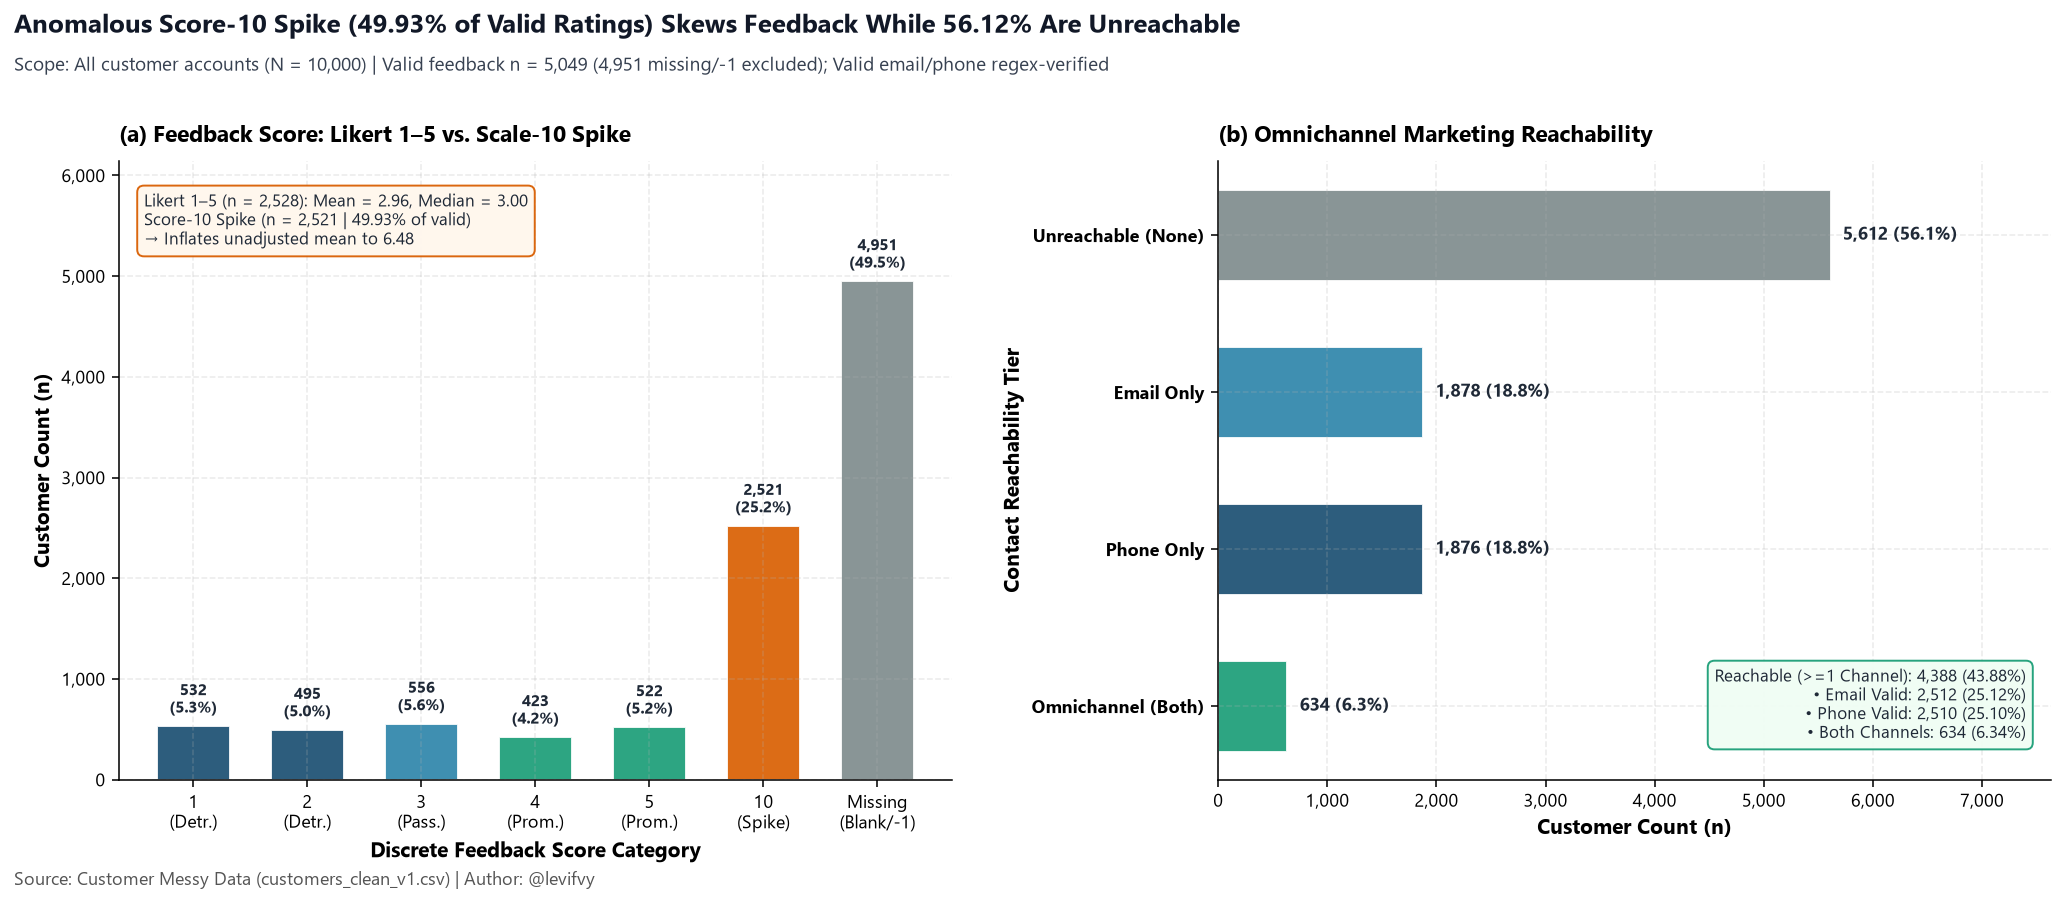

In [10]:
fig_e4_fb = plot_e4_feedback_and_reachability(df_v1, save=True)
plt.show()
plt.close(fig_e4_fb)

**Visual Interpretation — Feedback Scale Distortion & Omnichannel Reachability (`Q3` Satisfaction & Retention):**
- **Bimodal Rating Scale Distortion (`KPI-6`):** Almost half of all accounts (`4,951`, `49.5%`) lack valid feedback (blanks or `-1` sentinel). Among the $n = 5,049$ valid ratings, **2,521 records (`49.93%` of valid; `25.2%` of total)** sit at an off-scale score of `10`, artificially inflating the unadjusted mean to `6.48`. Isolating the clean `1–5` Likert cohort ($n = 2,528$) reveals a balanced, neutral satisfaction baseline (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`), with Detractors (`1–2`: `1,027` [`40.6%` of Likert]) slightly outnumbering Promoters (`4–5`: `945` [`37.4%` of Likert]).
- **Severe Contact Unreachability (`KPI-4`):** Across $N = 10,000$ accounts, **5,612 (`56.12%`) are completely `Unreachable (None)`** due to missing or malformed emails/phone numbers. Only **4,388 (`43.88%`)** can be contacted via at least one verified channel (`1,878` [`18.78%`] `Email Only`, `1,876` [`18.76%`] `Phone Only`, and just `634` [`6.34%`] `Omnichannel (Both)`), creating an immediate CRM bottleneck for retention campaigns.

---

## 5. `[E5]` Bivariate Analysis — Segment Comparisons & Hypothesis Testing

### 5.1 Quantitative Segment Comparisons & Formal Hypothesis Tests

We next evaluate pairwise relationships across three analytical families using `src/analysis.py`:
1. **Continuous × Categorical (`Q2`, `Q3`):** `purchase_amount` compared across `gender`, `country`, `city`, ontology `age_group` cohorts, discrete `feedback_score`, and `contact_reachability` via One-way ANOVA ($F$) and Kruskal-Wallis ($H$) tests (both including and excluding `'Unknown'`/`'Missing'`).
2. **Continuous × Continuous (`Q2`, `Q3`):** Pairwise linear (Pearson $r$) and monotonic rank (Spearman $\rho$) correlations of `age`, `feedback_score_1_to_5`, `feedback_score` (all), and chronologically valid `tenure_days` with `purchase_amount`.
3. **Categorical × Categorical (`Q1`):** `city` × `country` contingency table, Pearson $\chi^2$ test of independence, and exact audit of cross-border geographic mismatches.

In [11]:
e5_seg_spend = compute_bivariate_segment_spend(df_v1)
e5_tests = run_bivariate_hypothesis_tests(df_v1)
e5_crosstab = compute_city_country_crosstab(df_v1)

print("=== [E5] BIVARIATE SEGMENT SPEND SUMMARY ===")
print(e5_seg_spend.round(2).to_string(index=False))

print("\n=== [E5] FORMAL BIVARIATE HYPOTHESIS TESTS (ANOVA / KRUSKAL / CORRELATION / CHI2) ===")
print(e5_tests.round(4).to_string(index=False))

print("\n=== [E5] CITY x COUNTRY CROSS-TABULATION & GEOGRAPHIC MISMATCHES ===")
print(e5_crosstab.round(2).to_string(index=False))

=== [E5] BIVARIATE SEGMENT SPEND SUMMARY ===
                dimension                 segment  n_segment  n_valid_spend  spend_coverage_pct  mean_spend  std_spend  median_spend  q1_spend  q3_spend  iqr_spend  total_spend  revenue_per_1k_valid
                   gender                    Male       3800            960               25.26     2474.16    1471.21       2521.68   1114.59   3808.19    2693.60   2375192.57            2474158.93
                   gender                  Female       3745            889               23.74     2458.40    1438.41       2388.78   1215.44   3787.77    2572.33   2185521.50            2458404.39
                   gender                 Unknown       2455            617               25.13     2402.76    1405.32       2460.06   1181.70   3535.63    2353.93   1482504.39            2402762.38
                  country                     USA       1679            395               23.53     2363.55    1412.40       2327.06   1173.84   3602.56    242

**Quantitative Interpretation (`E5`):**
- **Segment Spend Homogeneity (`Q2`):** Across every demographic, geographic, satisfaction, and reachability dimension, observed `purchase_amount` variations lie well within random sampling noise (`significant_at_0_05 == False` for all 13 categorical comparisons, all $p \ge 0.31$). Specifically, among known segments: `gender` (`Male` mean `$2,474.16` / median `$2,521.69` [$n = 960$] vs. `Female` mean `$2,458.40` / median `$2,388.78` [$n = 889$]; ANOVA $F = 0.0541, p = 0.8161$; Kruskal $H = 0.0481, p = 0.8265$), `country` (ranging from `USA` mean `$2,363.55` [$n = 395$] to `Australia` mean `$2,510.63` [$n = 413$]; $F = 0.6297, p = 0.6413$; $H = 2.5092, p = 0.6430$), `city` (ranging from `Kolkata` mean `$2,286.54` [$n = 264$] to `Chennai` mean `$2,562.51` [$n = 258$]; $F = 0.9386, p = 0.4752$; $H = 6.6429, p = 0.4670$), and `age_group` (ranging from `18-29` mean `$2,334.77` [$n = 134$] to `60+` mean `$2,556.18` [$n = 117$]; $F = 0.5038, p = 0.6798$; $H = 1.6209, p = 0.6547$) show no statistically significant differentiation.
- **Zero Linear or Monotonic Association with Spend (`Q2`, `Q3`):** Pairwise correlations with `purchase_amount` are near zero across `age` ($n = 600$, $r = 0.0430 [p = 0.2930]$, $\rho = 0.0457 [p = 0.2641]$), `feedback_score_1_to_5` ($n = 648$, $r = -0.0178 [p = 0.6508]$, $\rho = -0.0168 [p = 0.6688]$), all valid `feedback_score` ($n = 1,248$, $r = 0.0174 [p = 0.5384]$, $\rho = 0.0168 [p = 0.5527]$), and valid `tenure_days` ($n = 219$, $r = -0.0560 [p = 0.4098]$, $\rho = -0.0700 [p = 0.3027]$). Observational correlations neither indicate statistical dependence nor imply causal effects.
- **Structural Geographic Contradiction (`Q1`):** Although all 8 known cities (`Hyderabad`, `Mumbai`, `Pune`, `Bangalore`, `Chennai`, `Delhi`, `Ahmedabad`, `Kolkata`) are Indian metropolitan areas, `city` and `country` are statistically independent ($\chi^2 = 32.1845, \text{dof} = 40, p = 0.8057$ across all $10,000$ rows; $\chi^2 = 19.2934, \text{dof} = 28, p = 0.8888$ across $7,348$ dual-known rows). Consequently, **5,888 records** (`58.88%` of the entire dataset; **80.13%** of the $7,348$ dual-known city-country records) pair an Indian city with `USA`, `Australia`, `Canada`, or `UK` (`63.85%–69.03%` row mismatch across every Indian city).

### 5.2 Bivariate Visual Exploration — Segment Homogeneity, Correlation & Geographic Integrity

To test whether transaction value clusters within specific demographic, geographic, age, satisfaction, or reachability cohorts — and to visually audit cross-column geographic consistency — we generate four multi-panel bivariate diagnostics (`src/visualization.py`).

Saved figure: assets/charts/e5_bivariate_spend_by_demographics.png


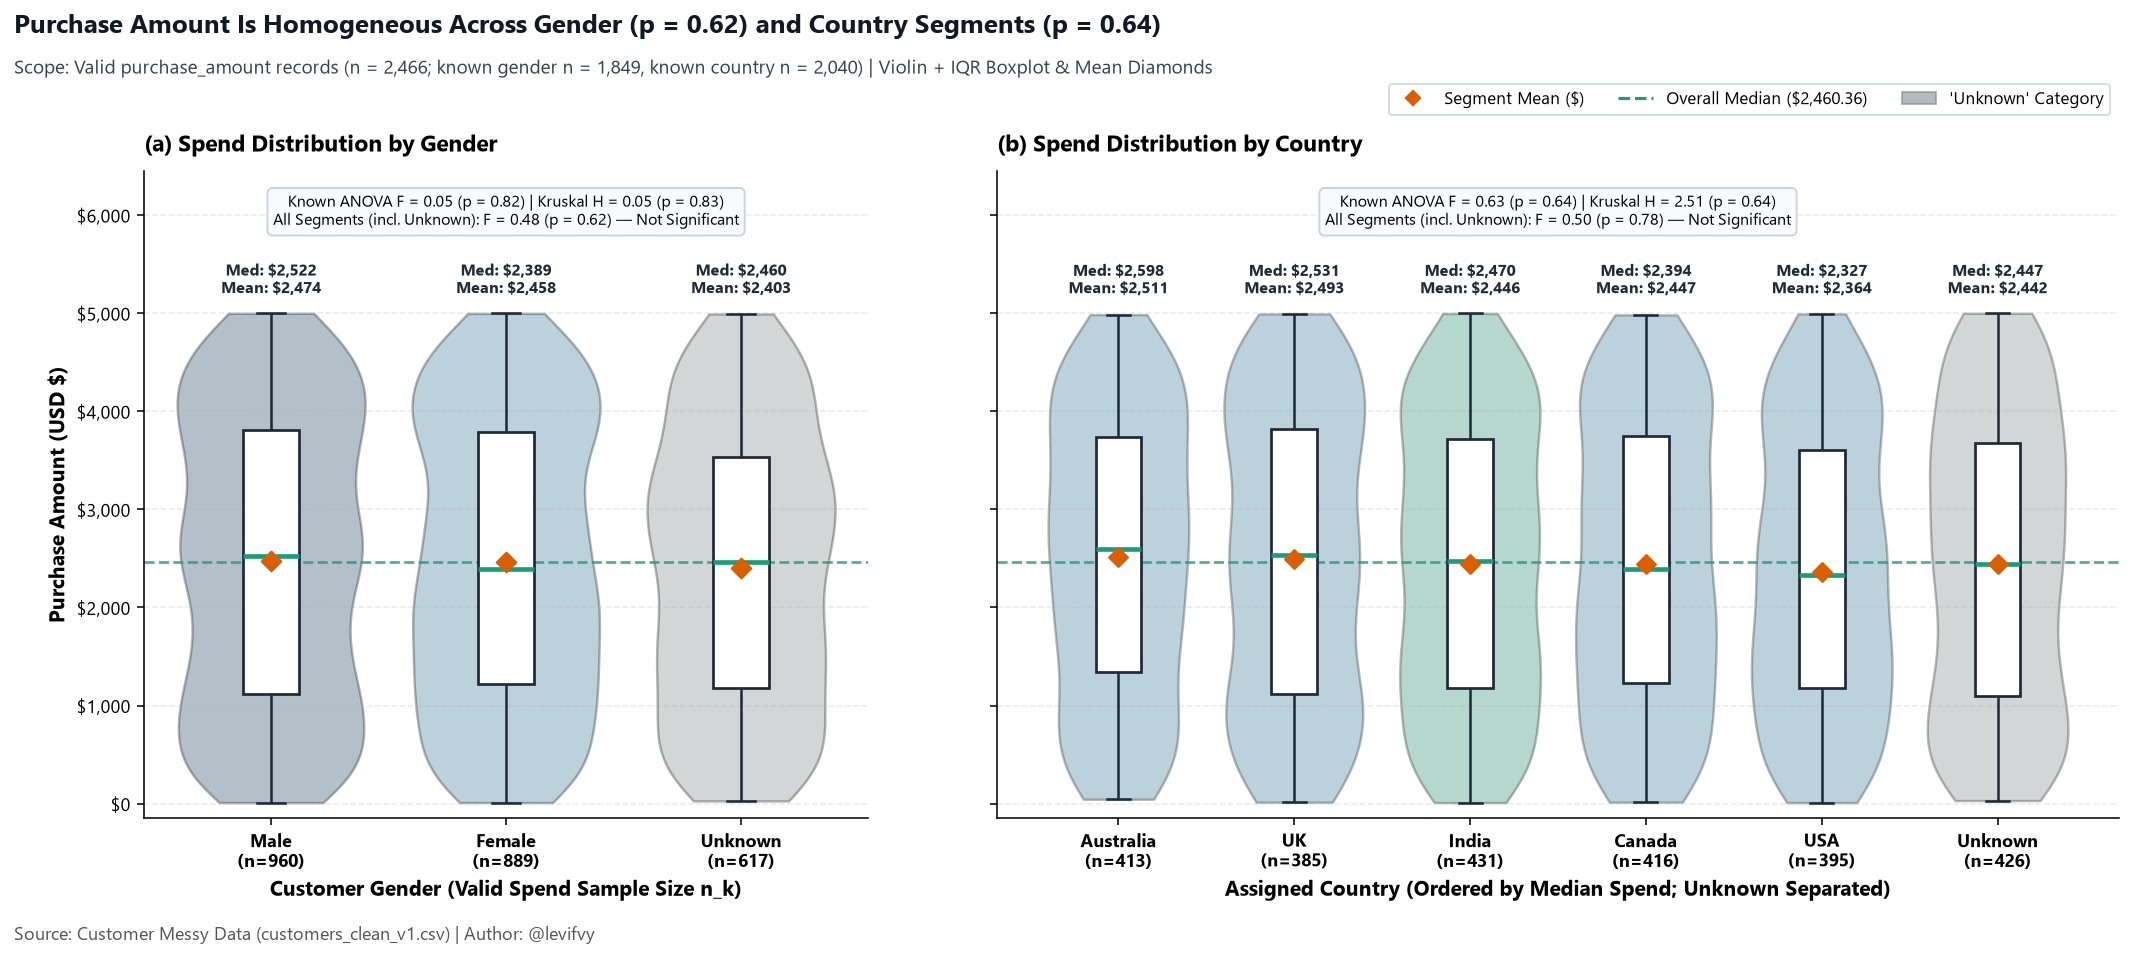

In [12]:
fig_e5_demo = plot_e5_spend_by_demographics(df_v1, save=True)
plt.show()
plt.close(fig_e5_demo)

**Visual Interpretation — Spend by Gender & Country (`Q2` High-Value Segments):**
- **Gender Homogeneity:** Across $n = 2,466$ valid spenders, violin densities and IQR boxes align closely across `Male` ($n_k = 960$, `mean = $2,474.16`, `median = $2,521.69`), `Female` ($n_k = 889$, `mean = $2,458.40`, `median = $2,388.78`), and `'Unknown'` ($n_k = 617$, `mean = $2,402.76`, `median = $2,460.06`). Neither known-gender tests (`ANOVA F = 0.05, p = 0.82`; `Kruskal-Wallis H = 0.05, p = 0.83`) nor all-segment tests (`F = 0.48, p = 0.62`) approach statistical significance.
- **Country Homogeneity:** Ordering countries by median spend from `Australia` ($n_k = 413$, `median = $2,597.60`, `mean = $2,510.63`) down to `USA` ($n_k = 395$, `median = $2,327.06`, `mean = $2,363.55`) — alongside `India` ($n_k = 431$, `median = $2,469.79`) and `'Unknown'` ($n_k = 426$, `median = $2,446.78`) — shows nearly identical platykurtic spreads (`known ANOVA F = 0.63, p = 0.64`; `Kruskal H = 2.51, p = 0.64`; `all-segment p = 0.78`).

Saved figure: assets/charts/e5_bivariate_spend_by_city_age.png


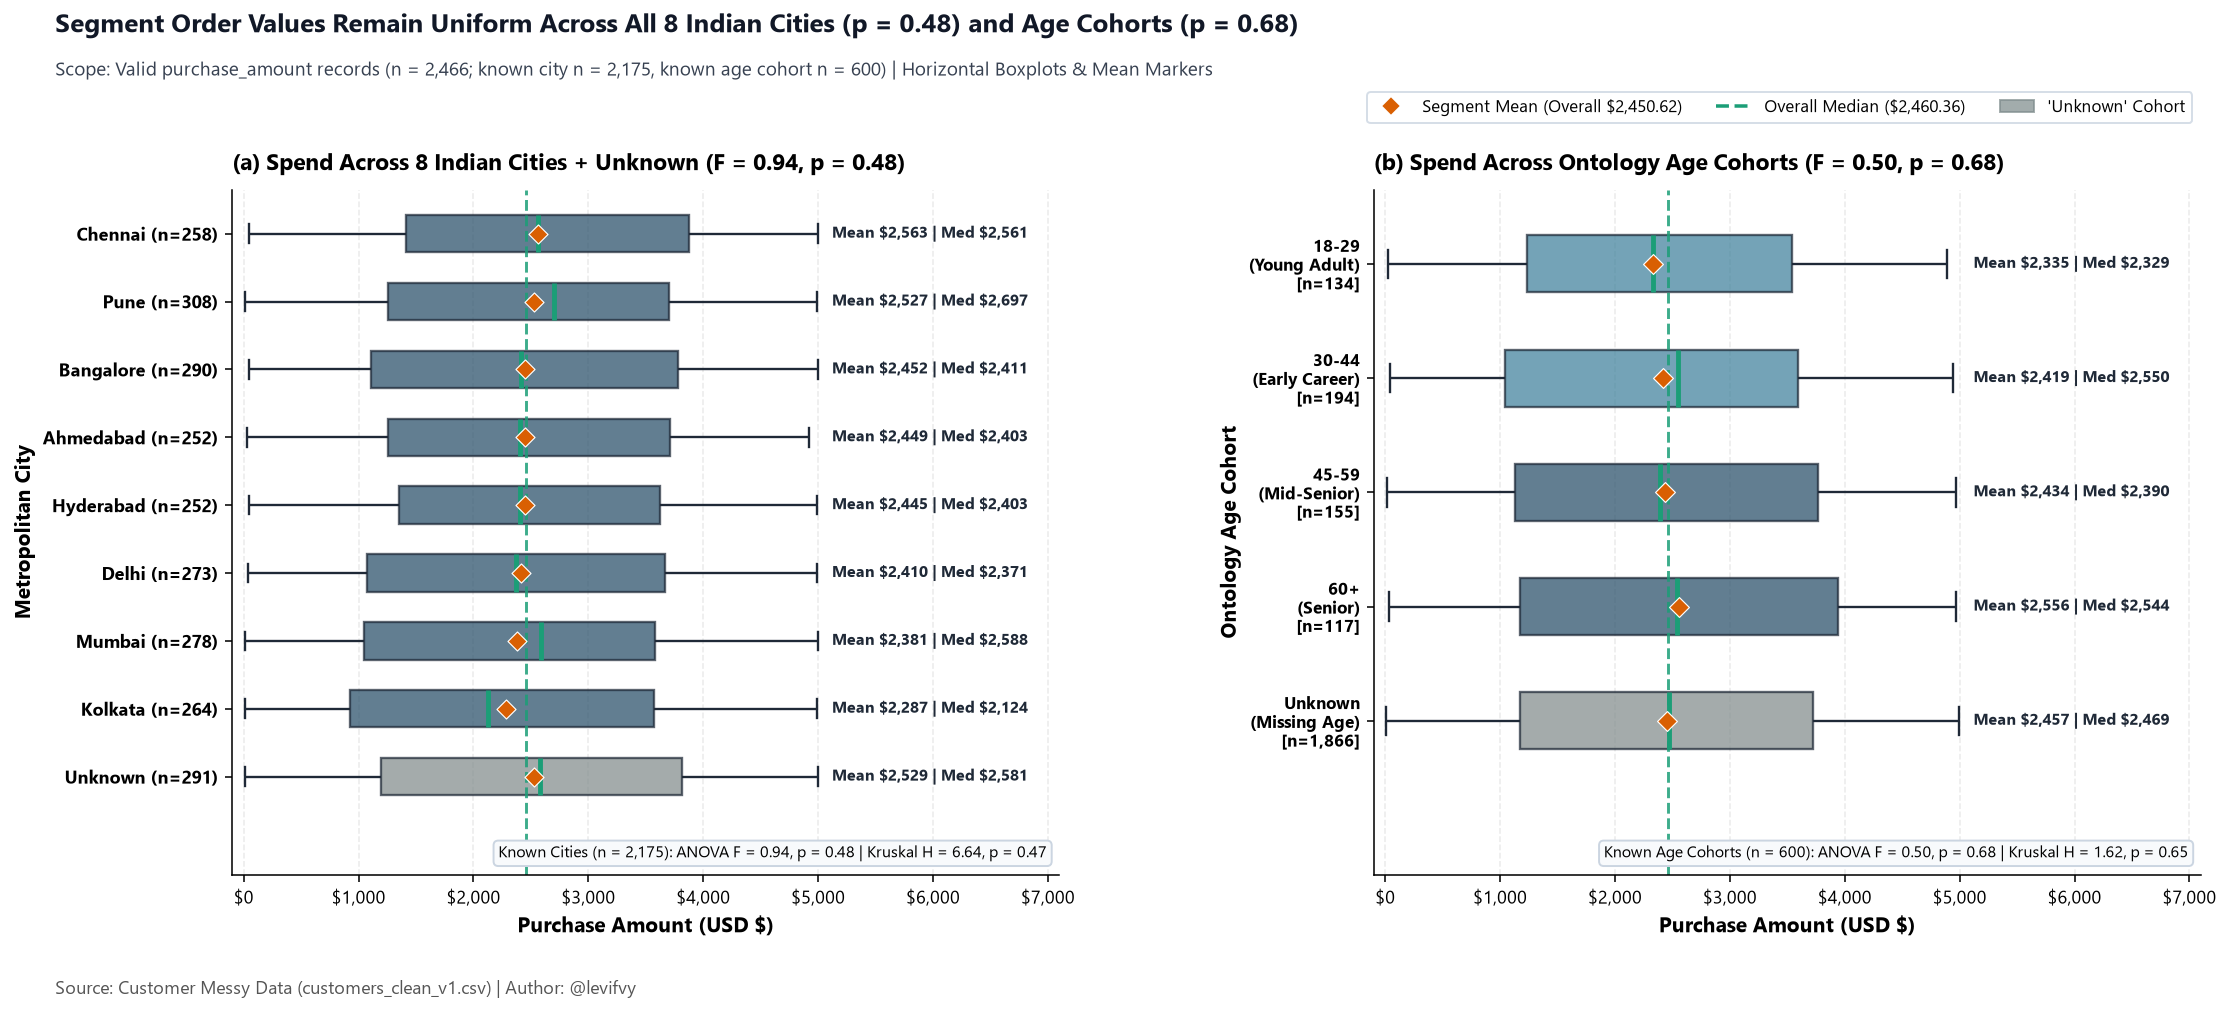

In [13]:
fig_e5_city_age = plot_e5_spend_by_city_and_age(df_v1, save=True)
plt.show()
plt.close(fig_e5_city_age)

**Visual Interpretation — Spend Across Indian Cities & Ontology Age Cohorts (`Q2` High-Value Segments):**
- **Metropolitan Cities ($n = 2,175$ known; $n = 2,466$ total):** Segment means span a narrow band from `Chennai` (`$2,562.51`, `median = $2,561.14`, $n_k = 258$) and `Pune` (`$2,526.88`, `median = $2,697.49`, $n_k = 308$) to `Kolkata` (`$2,286.54`, `median = $2,124.33`, $n_k = 264$), with `'Unknown'` at `$2,529.39` ($n_k = 291$). Formal omnibus tests (`known ANOVA F = 0.94, p = 0.48`; `Kruskal H = 6.64, p = 0.47`) confirm observed rank differences reflect random sampling variation rather than structural city-level spend premiums.
- **Ontology Age Cohorts ($n = 600$ known; $n = 1,866$ `'Unknown'`):** Comparing `18-29 (Young Adult)` (`mean = $2,334.77`, $n_k = 134$), `30-44 (Early Career)` (`$2,418.87`, $n_k = 194$), `45-59 (Mid-Senior)` (`$2,433.83`, $n_k = 155$), and `60+ (Senior)` (`$2,556.18`, $n_k = 117$) yields `ANOVA F = 0.50, p = 0.68` (`Kruskal H = 1.62, p = 0.65`), confirming that customer age brackets do not segment order value; moreover, `'Unknown'` age accounts ($n_k = 1,866$, `mean = $2,457.01`) match known-age spend (`all-segment p = 0.80`), supporting unbiased `NaN` retention.

Saved figure: assets/charts/e5_bivariate_age_vs_spend.png


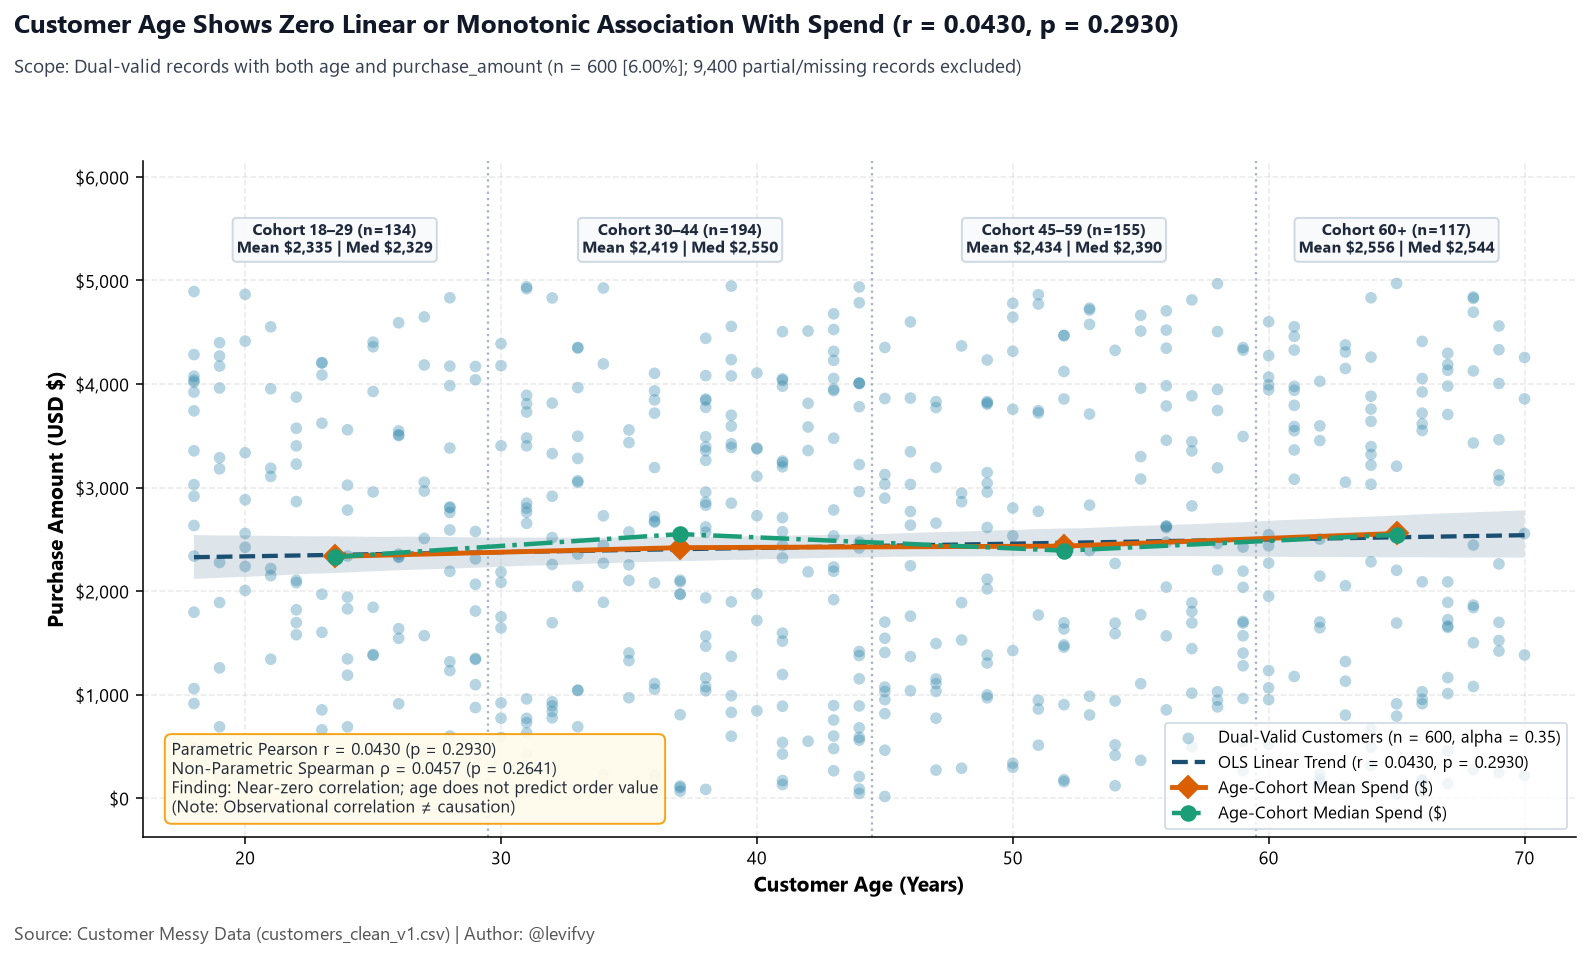

In [14]:
fig_e5_scatter = plot_e5_age_vs_spend(df_v1, save=True)
plt.show()
plt.close(fig_e5_scatter)

**Visual Interpretation — Continuous Age vs. Purchase Amount (`Q2` Revenue Drivers):**
- Plotting all $n = 600$ dual-valid customer records (`6.00%` of dataset; $9,400$ missing `age` and/or `purchase_amount`) with `alpha = 0.35` transparency reveals a uniform rectangular cloud across `18–70` years and `$10–$4,999`.
- Both the OLS linear regression line (`Pearson r = 0.0430, p = 0.2930`) and rank-order association (`Spearman ρ = 0.0457, p = 0.2641`) are flat, and the overlaid cohort mean/median trajectories remain anchored near `~$2,450`. Observational correlation is statistically indistinguishable from zero (and, per statistical governance, implies no causal relationship).

Saved figure: assets/charts/e5_bivariate_feedback_and_geo_mismatch.png


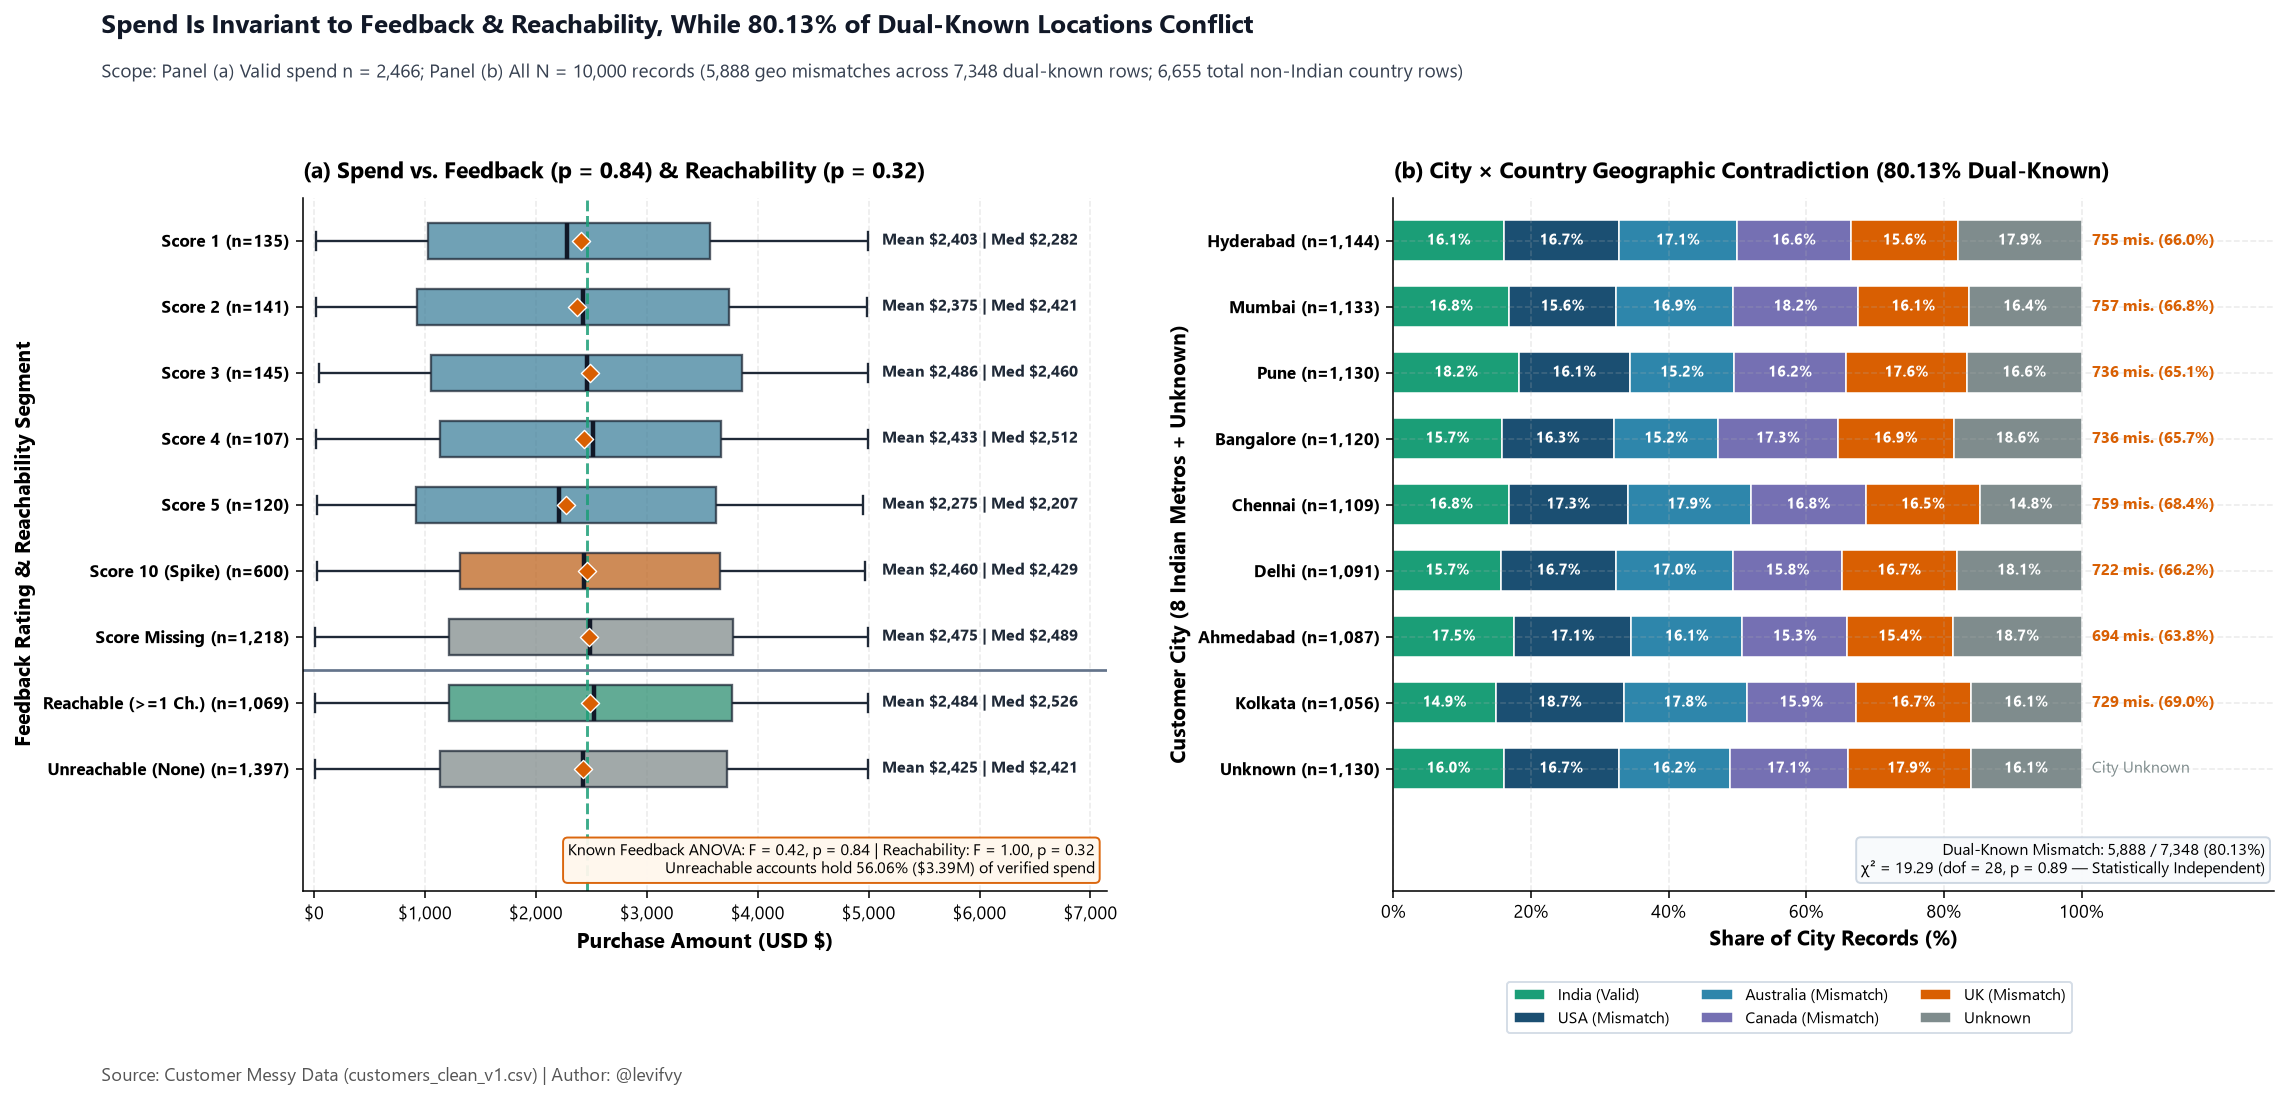

In [15]:
fig_e5_diag = plot_e5_feedback_and_geo_mismatch(df_v1, save=True)
plt.show()
plt.close(fig_e5_diag)

**Visual Interpretation — Feedback/Reachability Spend Invariance (`Q3`) & City × Country Contradiction (`Q1`):**
- **Panel (a) — Satisfaction & Reachability vs. Spend (`Q3`):** Order values do not vary across discrete `feedback_score` ratings `1–5` and the `Score 10` spike (`known ANOVA F = 0.42, p = 0.84`; `Score 10` mean `$2,460.06` [$n_k = 600$] vs. `Likert 1–5` ratings ranging `$2,275–$2,486`), indicating high spenders are just as likely to be Detractors as Promoters. Crucially, `Reachable (>=1 Ch.)` customers ($n_k = 1,069$, `mean = $2,483.83`) and `Unreachable (None)` customers ($n_k = 1,397$, `mean = $2,425.20`) spend equivalently (`F = 1.00, p = 0.32`), exposing **$3,388,004.29 (`56.06%` of verified revenue)** locked inside accounts that marketing cannot currently contact.
- **Panel (b) — Structural Geographic Contradiction (`Q1`):** Although every known city (`Hyderabad`, `Mumbai`, `Pune`, `Bangalore`, `Chennai`, `Delhi`, `Ahmedabad`, `Kolkata`) is located in India, each city row distributes ~`15%–19%` of its records uniformly across `India`, `USA`, `Australia`, `Canada`, `UK`, and `Unknown` (`χ² = 19.29, dof = 28, p = 0.89` across $n = 7,348$ dual-known rows — complete statistical independence). This synthetic/corrupted country assignment generates **5,888 exact `is_geo_mismatch` records** (**80.13%** of `7,348` dual-known records; **58.88%** of all `10,000` records, out of `6,655` total non-Indian country rows including `767` with `'Unknown'` city).

---

## 6. `[E6]` Answers to Guiding Business Questions & Essential Level Conclusions

To close the Essential EDA milestone (`E1–E6`), we first compute the consolidated canonical KPI table (`KPI-1` through `KPI-6` per `specs/ontology.md` §4) via `src/analysis.py` and then synthesize evidence-backed answers to `Q1`, `Q2`, and `Q3`.

In [16]:
e6_kpis = compute_research_question_kpis(df_v1)

print("=== [E6] CANONICAL RESEARCH QUESTION KPI SUMMARY (KPI-1 TO KPI-6) ===")
print(e6_kpis.round(2).to_string(index=False))

=== [E6] CANONICAL RESEARCH QUESTION KPI SUMMARY (KPI-1 TO KPI-6) ===
kpi_id business_question                                       kpi_name                                                               indicator  n_numerator  n_denominator  primary_value              unit  secondary_value               secondary_metric                                                                                                                                  notes
 KPI-1                Q1              Valid Attribute Coverage Rate (%)                                                      Age Valid Coverage         2465          10000          24.65               pct            43.70                 mean_age_years                                                                                             Median age=43.00y, SD=15.30y (range 18-70)
 KPI-1                Q1              Valid Attribute Coverage Rate (%)              Demographics & Location Coverage (Gender / City / Country)         88

### 6.1 Evidence-Backed Answers to the Three Guiding Business Questions (`Q1`, `Q2`, `Q3`)

Building on the univariate profiles (`E4`), bivariate hypothesis tests (`E5`), and canonical KPI consolidation (`KPI-1` through `KPI-6` in `e6_research_questions_kpis.csv`), we answer the three guiding business questions below. Because raw ingestion defects affected roughly three-quarters of continuous records, every conclusion states valid data coverage upfront and anchors exclusively to verified observations (`N = 10,000` cleaned accounts in `customers_clean_v1.csv`).

---

#### `Q1` — Customer Demographics & Geographic Footprint (`KPI-1`)

**Answer:** Among customers with verified demographic records (valid `age` coverage is `24.65%`, $n = 2,465$; known `gender` coverage is `75.45%`, $n = 7,545$), the active customer base is gender-balanced and evenly distributed across adult working ages (`18–70` years, centered near `43` years). However, while known `city` records (`88.70%` coverage, $n = 8,870$) consist exclusively of eight Indian metropolitan areas, reported `country` labels (`82.96%` coverage, $n = 8,296$) are statistically independent of city, leaving **80.13%** of dual-known geographic profiles with a cross-border contradiction.

- **Quantitative Evidence:**
  - **Adult Age Distribution (`KPI-1`, `e4_univariate_numeric_stats.csv`):** Valid `age` is available for $n = 2,465$ of $10,000$ accounts (`24.65%` coverage; $7,535$ records [`75.35%`] contained blanks [`2,576`] or impossible sentinels `-5` [`2,506`] and `200` [`2,453`], remediated to `NaN`). Verified ages span `18.00` to `70.00` years in a flat, symmetric spread: `mean = 43.70` years (`SD = 15.30` years, standard deviation around the mean) and `median = 43.00` years (`IQR = 27.00` years, interquartile range covering the middle 50% from `Q1 = 31.00` to `Q3 = 58.00`; `skewness = 0.0602`).
  - **Gender Parity & Metropolitan Balance (`KPI-1`, `e4_univariate_categorical_counts.csv`):** Standardized `gender` ($n = 7,545$ known; $2,455$ [`24.55%`] `'Unknown'`) is evenly split between `Male` ($n = 3,800$, `50.36%` of known / `38.00%` of total) and `Female` ($n = 3,745$, `49.64%` of known / `37.45%` of total). Known `city` ($n = 8,870$; $1,130$ [`11.30%`] `'Unknown'`) is uniformly distributed across eight Indian metros, ranging from `Kolkata` ($n = 1,056$, `11.91%` of known) to `Hyderabad` ($n = 1,144$, `12.90%` of known).
  - **Structural Geographic Mismatch (`KPI-1`, `e5_city_country_crosstab.csv`, `e5_bivariate_hypothesis_tests.csv`):** Known `country` ($n = 8,296$; $1,704$ [`17.04%`] `'Unknown'`) is split almost equally (~`20%` of known each) across `USA` ($1,679$), `Australia` ($1,660$), `Canada` ($1,658$), `UK` ($1,658$), and `India` ($1,641$), totaling $6,655$ non-Indian country rows (`767` with `'Unknown'` city). Across the $n = 7,348$ accounts where both `city` and `country` are known, **5,888 accounts (`80.13%` of dual-known; `58.88%` of all $10,000$ accounts)** pair an Indian metro with `USA`, `Australia`, `Canada`, or `UK` (`63.85%` to `69.03%` row mismatch in every city). A Pearson Chi-square test of categorical independence confirms no association between reported `city` and `country` ($\chi^2 = 19.2934, \text{dof} = 28, p = 0.8888$ on $n = 7,348$ dual-known records; $\chi^2 = 32.1845, \text{dof} = 40, p = 0.8057$ across all $10,000$ records). **Operational Recommendation (Data Engineering / CRM):** Enforce a lookup-table constraint linking `city` to `country` at account registration and treat `city` (not `country`) as the primary geographic reporting key until historical country labels are reconciled.
- **Cited Charts:** [`e4_univariate_age_distribution.png`](../assets/charts/e4_univariate_age_distribution.png), [`e4_univariate_demographics_counts.png`](../assets/charts/e4_univariate_demographics_counts.png), [`e5_bivariate_feedback_and_geo_mismatch.png`](../assets/charts/e5_bivariate_feedback_and_geo_mismatch.png).
- **Data Quality Caveat:** Because `75.35%` of `age` values are missing after sentinel removal, single-value median imputation was intentionally rejected to avoid compressing age dispersion (`SD` would drop artificially from `15.30` to `7.60` years); additionally, `is_geo_mismatch` (`5,888` rows) invalidates unadjusted country-level market sizing.

---

#### `Q2` — Revenue Distribution & High-Value Segments (`KPI-2`, `KPI-3`)

**Answer:** Verified `purchase_amount` is available for **24.66%** of accounts ($n = 2,466$), totaling **`$6,043,218.46`** with a symmetric, wide transaction spread centered at a mean of **`$2,450.62`** and a median of **`$2,460.36`**. Formal parametric and non-parametric hypothesis tests show **no statistically significant spending differences** across gender, country, city, or age cohorts, indicating that high-value purchasing behavior is distributed uniformly across demographic and geographic groups rather than concentrated in a specific demographic niche.

- **Quantitative Evidence:**
  - **Order Value & Normalized Revenue Baseline (`KPI-2`, `KPI-3`, `e4_univariate_numeric_stats.csv`, `e6_research_questions_kpis.csv`):** Across $n = 2,466$ valid orders (`24.66%` coverage; $7,534$ rows [`75.34%`] were blank [`2,500`], `'N/A'` [`2,533`], or `-999` [`2,501`]), verified revenue totals **`$6,043,218.46`**. Order values span `$10.31` to `$4,998.67` symmetrically (`skewness = 0.0139`), with parametric `mean = $2,450.62` (`SD = $1,442.83`) and non-parametric `median = $2,460.36` (`IQR = $2,574.50`, middle 50% spread from `Q1 = $1,159.39` to `Q3 = $3,733.88`). Normalized **KPI-3** stands at **`$2,450,615.76` per 1,000 valid customers**.
  - **Demographic & Geographic Spend Homogeneity (`KPI-3`, `e5_bivariate_spend_by_segment.csv`, `e5_bivariate_hypothesis_tests.csv`):** Neither One-way ANOVA ($F$, comparing group means) nor Kruskal-Wallis ($H$, comparing group rank distributions) detects statistically significant variation across any known segment ($\alpha = 0.05$):
    - *Gender ($n = 1,849$ known valid orders):* `Male` averages `$2,474.16` (`median = $2,521.69`, `$2,474,158.93` per 1,000 valid, $n = 960$) vs. `Female` `$2,458.40` (`median = $2,388.78`, `$2,458,404.39` per 1,000 valid, $n = 889$); $F = 0.0541, p = 0.8161$; $H = 0.0481, p = 0.8265$.
    - *Country ($n = 2,040$ known valid orders):* Segment means range from `USA` (`$2,363.55`, `$2,363,551.65/1k`, $n = 395$) to `Australia` (`$2,510.63`, `$2,510,634.70/1k`, $n = 413$); $F = 0.6297, p = 0.6413$; $H = 2.5092, p = 0.6430$.
    - *City ($n = 2,175$ known valid orders):* Segment means range from `Kolkata` (`$2,286.54`, `$2,286,536.33/1k`, $n = 264$) to `Chennai` (`$2,562.51`, `$2,562,508.53/1k`, $n = 258$); $F = 0.9386, p = 0.4752$; $H = 6.6429, p = 0.4670$.
    - *Age Cohorts & Continuous Age ($n = 600$ dual-valid age-and-spend records):* Cohort means range from `18-29 (Young Adult)` (`$2,334.77`, `$2,334,765.97/1k`, $n = 134$) to `60+ (Senior)` (`$2,556.18`, `$2,556,179.32/1k`, $n = 117$); $F = 0.5038, p = 0.6798$; $H = 1.6209, p = 0.6547$. Continuous `age` shows negligible linear (Pearson $r = 0.0430, p = 0.2930$) and rank-order monotonic (Spearman $\rho = 0.0457, p = 0.2641$) association with `purchase_amount`. **Operational Recommendation (Marketing & Merchandising):** Reallocate VIP retention budgets away from demographic or city-based targeting toward behavioral value tiers (`spend_tier`, isolating orders `> $3,500` near `Q3 = $3,733.88`).
- **Cited Charts:** [`e4_univariate_purchase_distribution.png`](../assets/charts/e4_univariate_purchase_distribution.png), [`e5_bivariate_spend_by_demographics.png`](../assets/charts/e5_bivariate_spend_by_demographics.png), [`e5_bivariate_spend_by_city_age.png`](../assets/charts/e5_bivariate_spend_by_city_age.png), [`e5_bivariate_age_vs_spend.png`](../assets/charts/e5_bivariate_age_vs_spend.png).
- **Data Quality Caveat:** Because `75.34%` of `purchase_amount` records are missing and missingness occurs independently of `age`, joint age-and-spend analyses rest on $n = 600$ records (`6.00%` of all accounts), requiring explicit `is_purchase_missing` and `is_age_missing` indicator audits in Medium Level (`M1`) to verify that missingness is not systematically associated with other attributes.

---

#### `Q3` — Customer Satisfaction, Retention & Channel Reachability (`KPI-4`, `KPI-5`, `KPI-6`)

**Answer:** Valid `feedback_score` covers **50.49%** of accounts ($n = 5,049$), but nearly half of those ratings (**49.93%**, $n = 2,521$) sit at an anomalous off-scale value of `10`, while clean `1–5` Likert ratings ($n = 2,528$) reflect neutral sentiment (`mean = 2.96`, `median = 3.00`); neither satisfaction nor chronologically valid customer tenure (`median = 638.00` days across $n = 855$ valid dual-date records) is associated with order value. Operationally, the sharpest commercial vulnerability is contactability: only **43.88%** ($4,388$) of customers are reachable via email or phone, leaving **56.12%** ($5,612$) unreachable and **`$3,388,004.29` (`56.06%`) of verified spend** inaccessible to retention campaigns.

- **Quantitative Evidence:**
  - **Bimodal Satisfaction Scale & Zero Spend Association (`KPI-6`, `e4_univariate_numeric_stats.csv`, `e5_bivariate_hypothesis_tests.csv`, `e6_research_questions_kpis.csv`):** After removing blanks (`2,462`) and `-1` sentinels (`2,489`), $n = 5,049$ accounts (`50.49%` coverage) hold valid ratings, split between `2,521` anomalous `10` scores (`49.93%` of valid ratings, inflating raw `mean` to `6.48`) and `2,528` standard `1–5` Likert ratings (`25.28%` of total accounts). Within `feedback_score_1_to_5` ($n = 2,528$), sentiment is neutral-to-critical (`mean = 2.96`, `SD = 1.42`, `median = 3.00`, `IQR = 2.00`), with `Detractors (1–2)` ($n = 1,027$; `40.62%` of Likert / `20.34%` of all valid) outnumbering `Promoters (4–5)` ($n = 945$; `37.38%` of Likert / `18.72%` of all valid), alongside `556` `Passives (3)` (`11.01%` of all valid). Order value shows zero association with `feedback_score_1_to_5` ($n = 648$, Pearson $r = -0.0178, p = 0.6508$; Spearman $\rho = -0.0168, p = 0.6688$; ANOVA $F = 0.3520, p = 0.8427$) or full `feedback_score` ($n = 1,248$, $r = 0.0174, p = 0.5384$).
  - **Chronological Integrity & Lifecycle Tenure (`KPI-5`, `e4_univariate_numeric_stats.csv`, `e5_bivariate_hypothesis_tests.csv`, `e6_research_questions_kpis.csv`):** Only $n = 1,684$ accounts (`16.84%` coverage) possess both valid `signup_date` (`49.96%` overall coverage) and `last_purchase_date` (`33.48%` overall coverage). Among these $1,684$ dual-date accounts, chronological integrity (`last_purchase_date >= signup_date`) holds for **`50.77%`** ($n = 855$), while **`829` accounts (`49.23%`)** exhibit inverted dates (`is_date_inverted == True`). Across chronologically valid accounts ($n = 855$, `8.55%` of total), `tenure_days` has `median = 638.00` days (`IQR = 710.50` days, `Q1 = 299.50`, `Q3 = 1,010.00`, range `0–1,925` days) and `mean = 688.59` days (`SD = 464.11` days), and exhibits no statistically significant association with `purchase_amount` ($n = 219$, Pearson $r = -0.0560, p = 0.4098$; Spearman $\rho = -0.0700, p = 0.3027$).
  - **Omnichannel Reachability Exposure (`KPI-4`, `e4_univariate_categorical_counts.csv`, `e5_bivariate_spend_by_segment.csv`, `e5_bivariate_hypothesis_tests.csv`):** Across all $10,000$ accounts, valid `email` covers `25.12%` ($2,512$) and valid `phone_number` covers `25.10%` ($2,510$). Combined, **`43.88%`** ($4,388$) of accounts are reachable via at least one channel — `634` (`6.34%`) `Omnichannel (Both)`, `1,878` (`18.78%`) `Email Only`, and `1,876` (`18.76%`) `Phone Only` — while **`56.12%`** ($5,612$) are `Unreachable (None)`. Because reachable customers (`mean = $2,483.83`, `median = $2,525.94`, $n = 1,069$) and unreachable customers (`mean = $2,425.20`, `median = $2,421.13`, $n = 1,397$) spend at statistically indistinguishable levels (ANOVA $F = 1.0000, p = 0.3174$; Kruskal-Wallis $H = 1.0236, p = 0.3117$), **`$3,388,004.29` (`56.06%` of `$6,043,218.46` total verified spend; `56.65%` of valid orders)** sits inside unreachable accounts. **Operational Recommendation (CRM & Checkout Engineering):** Deploy real-time RFC email and 10-digit mobile verification at checkout and incentivize contact-profile completion upon login to recover retention access to that `$3.39M` revenue pool.
- **Cited Charts:** [`e4_univariate_feedback_reachability.png`](../assets/charts/e4_univariate_feedback_reachability.png), [`e5_bivariate_feedback_and_geo_mismatch.png`](../assets/charts/e5_bivariate_feedback_and_geo_mismatch.png).
- **Data Quality Caveat:** Unfiltered aggregation of `feedback_score` (`mean = 6.48`) or raw date differences (including `829` negative-tenure inversions) severely distorts satisfaction and lifecycle metrics; all downstream models must isolate `is_score_10_spike` (`2,521` rows) and exclude `is_date_inverted` (`829` rows) before computing tenure or sentiment KPIs.

### 6.2 Preliminary Conclusions & Bridge to Medium Level (`M1–M7`)

Completing the **Essential Level (`E1–E6`)** establishes three foundational empirical insights for executive decision-making:

1. **Data Integrity Governs Commercial Visibility:** Roughly three-quarters of continuous attributes (`age` at `24.65%` valid coverage; `purchase_amount` at `24.66%`), nearly half of dual-date records (`49.23%` chronologically inverted), `80.13%` of dual-known geographic pairs (`5,888` Indian-city vs. non-Indian-country mismatches), and `49.93%` of valid feedback ratings (`2,521` off-scale `10` entries) suffered from upstream ingestion corruption. Separating domain sentinels from genuine observations was prerequisite to recovering unbiased baselines.
2. **Spend Is Behaviorally Wide Rather Than Demographically Stratified:** Verified customer spend (`$6,043,218.46` across $n = 2,466$ orders; `mean = $2,450.62`, `median = $2,460.36`, `IQR = $2,574.50`) exhibits statistical parity across gender ($p = 0.8161$), country ($p = 0.6413$), city ($p = 0.4752$), age ($p = 0.2930$), satisfaction ($p = 0.6508$), and tenure ($p = 0.4098$). Customer segmentation must therefore anchor on transaction value tiers rather than demographic proxies.
3. **Contact Unreachability Is the Primary Revenue Risk:** With `56.12%` of accounts ($5,612$) lacking both a valid email and a valid phone number — representing `$3,388,004.29` (`56.06%`) of verified revenue — remediating CRM capture and checkout validation offers immediate operational leverage.

#### Strategic Roadmap into the Medium Level (`M1–M7`)
To translate these baseline findings into multi-dimensional segment strategy and the CEO Executive Report, the **Medium Level (`feature/03-outliers-feature-engineering` and `feature/04-correlation-trends-report`)** will execute five targeted analytical steps:
- **Variance-Preserving Imputation & Missingness Rationale (`M1`):** Formally document why `NaN` retention + explicit indicator flags (`is_age_missing`, `is_purchase_missing`) outperforms mean/median imputation on `75%`-missing continuous variables.
- **Formal Tukey IQR Outlier Diagnostics (`M2`):** Apply $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$ fences across `age`, `purchase_amount`, and chronologically valid `customer_tenure_days` to verify boundary behavior and justify retention vs. winsorization rules.
- **Multi-Dimensional Segment Aggregations (`M3`) & Behavioral Feature Engineering (`M4`):** Construct standardized ontology cohorts (`age_group`, fixed-threshold `spend_tier`, `feedback_tier`, `contact_reachability_tier`, `customer_tenure_days`) and cross-tabulate them via `groupby`, `agg`, and `pivot_table` to isolate reachable high-value (`>$3,500`) customer pockets.
- **Multivariate Correlation, Temporal Cohort Evolution & CEO Report (`M5–M7`):** Evaluate full Pearson ($r$) and Spearman ($\rho$) correlation matrices across engineered features, examine acquisition and purchase trends over valid timestamps, and synthesize actionable recommendations in `reports/executive_report.md`.

---

## 7. `[M1]` Cleaning Decisions & Methodological Justification

While Section 3 (`[E3]`) executed the baseline type-casting pipeline (`customers_clean_v1.csv`, `10,000 × 15`), rigorous exploratory analysis requires documenting the **statistical and domain rationale (*why*)** behind every column retention, deduplication, sentinel remediation, imputation, and anomaly-flagging rule, and advancing the dataset to the full ontology-compliant **`customers_clean_v2.csv` (`10,000` rows × `21` columns)** via `src/cleaning.py`.

### 7.1 Explicit Methodological Criteria Across Five Governance Pillars

1. **Full Column Retention & `snake_case` Standardization (`12 / 12` Raw Columns Retained; `0` Dropped):**
   - **Why zero columns were dropped:** Every raw attribute maps directly to one of the four canonical domain entities (`Customer`, `Demographics`, `Transaction`, `Interaction` in `specs/ontology.md` §1) and retains between **`24.65%`** (`age`, $n = 2,465$) and **`88.70%`** (`city`, $n = 8,870$) verified observations indispensable to answering `Q1`, `Q2`, and `Q3`. Dropping high-missingness columns (`age` at `75.35%` invalid, `purchase_amount` at `75.34%`, `Phone_number` at `74.90%`, `email` at `74.88%`) would eliminate **`$6,043,218.46`** in verified revenue (`KPI-2`/`KPI-3`), adult cohort profiling (`KPI-1`), and omnichannel reachability auditing (`KPI-4`).
   - **Why `snake_case`:** Standardizing mixed raw headers (`CustomerID`, `Signup_Date`, `Last_purchase_date`, `Phone_number` → `customer_id`, `signup_date`, `last_purchase_date`, `phone_number`) enforces PEP 8 attribute ergonomics and strict CI data-contract validation.

2. **Duplicate Resolution & Lossless Primary Key Reconstruction (`C00001`–`C10000`):**
   - **Empirical audit:** Full-row deduplication across all `10,000` raw records confirms **`0` exact row duplicates**. Although raw `CustomerID` contains `2,379` blanks (`23.79%`) and mixes `'C'`-prefixed identifiers (`2,561` rows, e.g., `'C2'`, `'C4'`) with bare integers (`5,060` rows, e.g., `'3'`, `'5'`), stripping the `'C'` prefix confirms **`0` colliding numeric IDs** and a **100.0% 1-to-1 positional match** (`int(id) == row_index + 1`) across all `7,621` populated entries.
   - **Decision rationale:** Reconstructing sequential 5-digit keys (`C00001`–`C10000`) is 100% deterministic and lossless, whereas dropping rows with blank `CustomerID` would needlessly discard `23.79%` of valid customer transactions and demographic profiles.

3. **Categorical `'Unknown'` Assignment vs. Continuous `NaN` Retention + Missingness Indicators:**
   - **Nominal & Categorical Attributes (`name`, `gender`, `city`, `country` → Explicit `'Unknown'`):** Missing entries (`11.30%` in `city`, `16.58%` in `name`, `17.04%` in `country`, `24.55%` in `gender`) are assigned an explicit `'Unknown'` token/category rather than mode-imputed or left as `NaN`. Mode imputation on `gender` (`Male = 3,800` vs. `Female = 3,745`) would assign all `2,455` blank records to `'Male'`, fabricating a **`+64.6%` surge** in Male representation (`38.00%` → `62.55%` of total); similarly, mode imputation on `city` (`Hyderabad = 1,144`) or `country` (`USA = 1,679`) would invent false market concentration across otherwise uniform distributions. Explicit `'Unknown'` levels guarantee that `groupby(..., observed=True)` and `pivot_table` (`M3`) account for all `10,000` customers without silent row attrition.
   - **Continuous Numerics (`age`, `purchase_amount`, `feedback_score`), Dates (`signup_date`, `last_purchase_date`), and Contacts (`email`, `phone_number` → `NaN`/`NaT` + Indicator Flags):** Domain sentinels (`-5` [`2,506`] and `200` [`2,453`] in `age`; `'N/A'` [`2,533`] and `'-999'` [`2,501`] in `purchase_amount`; `'-1'` [`2,489`] in `feedback_score`; `'not_a_date'` [`2,475`] and `'missing'` [`3,366`] in dates; `2,422` `@`-less emails; `'abc123'` [`2,586`] and `'0'` [`2,460`] in phones) encode missing/corrupted capture rather than real measurements. Coercing sentinels to `NaN`/`NaT` and pairing primary columns with boolean indicators (`is_age_missing`, `is_purchase_missing`, `has_valid_email`, `has_valid_phone`) preserves true parametric (`SD`) and non-parametric (`IQR`) dispersion while preventing phantom revenue (`$18.54M`), fabricated acquisition cohorts (`M6`), or unroutable CRM dispatches.

4. **Non-Destructive Cross-Column Contradiction & Scale-Anomaly Flags (`v2` Quality Schema):**
   - **`is_date_inverted` (`829` rows; `49.23%` of `1,684` dual-date accounts):** Flags records where `last_purchase_date < signup_date` so lifecycle `customer_tenure_days` ($n = 855$ valid) is protected from negative durations without deleting valid standalone dates.
   - **`is_geo_mismatch` (`5,888` rows; `80.13%` of `7,348` dual-known geo accounts):** Flags records pairing one of the 8 Indian metropolitan cities with `USA`, `Australia`, `Canada`, or `UK` ($\chi^2 p = 0.8888$), preserving raw `city` and `country` values for downstream audit (`A3`) while enabling clean geographic filtering.
   - **`is_score_10_spike` (`2,521` rows) & `feedback_score_1_to_5` ($n = 2,528$):** Isolates the off-scale `10` anomaly (`49.93%` of `5,049` valid ratings) by setting `10 → NaN` in `feedback_score_1_to_5` (`mean = 2.96`, `median = 3.00`) rather than remapping `10 → 5`, which would artificially inflate `Promoters (4–5)` by **`+266.8%`** (`945` → `3,466`).
   - **`completeness_score` (`float64`, `0.0`–`1.0`):** Captures row-wise valid attribute coverage across all 12 core columns (`mean = 0.5533`, `median = 0.5833`, range `0.1667`–`0.9167`).

5. **Trade-Offs & Missingness Mechanism Evaluation (MCAR Verification):**
   - Retaining `NaN` reduces complete-case sample size (`n = 2,465` for `age`, `n = 2,466` for `purchase_amount`, and `n = 600` for joint `age × purchase_amount`), trading narrower confidence intervals for **zero synthetic variance bias**. Complete-case estimation on valid observations is statistically unbiased when missingness is consistent with **Missing Completely at Random (MCAR)** — verified empirically below via Welch's two-sample $t$-test and Mann-Whitney $U$ tests across `is_age_missing` and `is_purchase_missing`.

In [17]:
from src.cleaning import (
    build_cleaning_decisions_audit,
    clean_customers,
    compute_imputation_variance_impact,
    export_m1_artifacts,
    load_raw_customers,
)

m1_paths = export_m1_artifacts()
df_raw_m1 = load_raw_customers()
df_v2 = clean_customers(df_raw_m1)
m1_audit = build_cleaning_decisions_audit(df_raw_m1, df_v2)
m1_impact = compute_imputation_variance_impact(df_v2)

print(f"Exported cleaned v2 dataset: {m1_paths['customers_clean_v2'].relative_to(REPO_ROOT).as_posix()}")
print(f"Cleaned v2 dataset shape: {df_v2.shape[0]:,} rows × {df_v2.shape[1]} columns")
print(
    "v2 quality flags summary: "
    f"has_valid_email={int(df_v2['has_valid_email'].sum()):,}, "
    f"has_valid_phone={int(df_v2['has_valid_phone'].sum()):,}, "
    f"is_date_inverted={int(df_v2['is_date_inverted'].sum()):,}, "
    f"is_geo_mismatch={int(df_v2['is_geo_mismatch'].sum()):,}, "
    f"is_age_missing={int(df_v2['is_age_missing'].sum()):,}, "
    f"is_purchase_missing={int(df_v2['is_purchase_missing'].sum()):,}, "
    f"is_score_10_spike={int(df_v2['is_score_10_spike'].sum()):,}, "
    f"feedback_1_to_5_valid={int(df_v2['feedback_score_1_to_5'].notna().sum()):,}, "
    f"mean_completeness={df_v2['completeness_score'].mean():.4f}"
)

audit_display_cols = [
    "raw_column",
    "clean_column",
    "target_dtype",
    "blank_count",
    "sentinel_count",
    "total_invalid",
    "invalid_pct",
    "valid_count",
    "valid_pct",
    "imputation_choice",
]
print("\n=== [M1] CLEANING & IMPUTATION DECISIONS AUDIT (12 ATTRIBUTES) ===")
print(m1_audit[audit_display_cols].to_string(index=False))

impact_display_cols = [
    "variable",
    "missing_pct",
    "strategy",
    "n_evaluated",
    "mean",
    "std",
    "std_change_pct",
    "q1",
    "median",
    "q3",
    "iqr",
    "iqr_change_pct",
]
print("\n=== [M1] IMPUTATION VARIANCE & IQR IMPACT EXPERIMENT ===")
print(m1_impact[impact_display_cols].round(2).to_string(index=False))

mcar_display_cols = [
    "variable",
    "mcar_check_target",
    "n_target_when_missing",
    "n_target_when_observed",
    "target_mean_when_missing",
    "target_mean_when_observed",
    "welch_t_stat",
    "welch_p_value",
    "mannwhitney_u_stat",
    "mannwhitney_p_value",
    "mcar_conclusion",
]
print("\n=== [M1] MISSINGNESS MECHANISM (MCAR) TWO-SAMPLE VERIFICATION ===")
print(m1_impact[mcar_display_cols].drop_duplicates().to_string(index=False))

Exported cleaned v2 dataset: data/processed/customers_clean_v2.csv
Cleaned v2 dataset shape: 10,000 rows × 21 columns
v2 quality flags summary: has_valid_email=2,512, has_valid_phone=2,510, is_date_inverted=829, is_geo_mismatch=5,888, is_age_missing=7,535, is_purchase_missing=7,534, is_score_10_spike=2,521, feedback_1_to_5_valid=2,528, mean_completeness=0.5533

=== [M1] CLEANING & IMPUTATION DECISIONS AUDIT (12 ATTRIBUTES) ===
        raw_column       clean_column   target_dtype  blank_count  sentinel_count  total_invalid  invalid_pct  valid_count  valid_pct                                                          imputation_choice
        CustomerID        customer_id            str         2379               0           2379        23.79         7621      76.21                    Deterministic positional reconstruction (100% lossless)
              Name               name            str         1658               0           1658        16.58         8342      83.42                  

**Methodological Interpretation (`M1` — Empirical Proof Against Single-Value Imputation):**
- **Catastrophic Variance (`~50.4%`) & Interquartile (`100%`) Collapse (`Q1`, `Q2`):** Replacing `75.35%` missing `age` ($7,535$ rows) with the valid median (`43.00` years) or mean (`43.70` years) compresses the sample standard deviation from **`15.30` years to `7.60` years** (**`-50.32%`** and **`-50.36%`**) and collapses the interquartile range by **`-100.00%`** (`IQR: 27.00 → 0.00` years, as both `Q1` and `Q3` collapse onto the constant spike). Identically, imputing `75.34%` missing `purchase_amount` ($7,534$ rows) with the median (`$2,460.36`) or mean (`$2,450.62`) slashes `SD` from **`$1,442.83` to `$716.40` / `$716.39`** (**`-50.35%`**) and annihilates `IQR` from **`$2,574.50` to `$0.00`** (**`-100.00%`**). Had median imputation been applied, the downstream `[M2]` Tukey outlier fences ($[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$) would degenerate to a zero-width point (`[43.00, 43.00]` and `[$2,460.36, $2,460.36]`), falsely flagging **every genuine non-median customer and transaction** as an outlier while fabricating **`$18,536,314.87`** in unverified spend!
- **Confirmed MCAR Missingness Independence (`Q1`, `Q2`):** Two-sample hypothesis tests confirm that retaining `NaN` introduces no selection bias across continuous metrics: verified `purchase_amount` does not differ between accounts with missing `age` ($n = 1,866$, `mean = $2,457.01`) and observed `age` ($n = 600$, `mean = $2,430.72`; Welch's $t = 0.3903, p = 0.6964$; Mann-Whitney $U = 565,943.5, p = 0.6855$), nor does verified `age` differ between accounts with missing `purchase_amount` ($n = 1,865$, `mean = 43.79` years) and observed `purchase_amount` ($n = 600$, `mean = 43.43` years; Welch's $t = 0.5086, p = 0.6112$; Mann-Whitney $U = 566,596.0, p = 0.6398$).
- **Expanded `v2` Quality Contract (`Q1`, `Q3`):** `customers_clean_v2.csv` (`10,000 × 21`) preserves 100% cell-for-cell backward compatibility with `v1` across the first 15 columns while embedding `is_geo_mismatch` (`5,888` rows), `is_age_missing` (`7,535`), `is_purchase_missing` (`7,534`), `is_score_10_spike` (`2,521`), `feedback_score_1_to_5` ($n = 2,528$ valid), and `completeness_score` (`mean = 0.5533`, `SD = 0.1180`) for downstream outlier (`M2`), segmentation (`M3`), and feature engineering (`M4`) workflows.

---

## 8. `[M2]` Outlier Detection & Treatment (Tukey IQR Rule)

Rigorous outlier governance in corrupted real-world data requires separating **two fundamentally distinct phenomena** before applying any mathematical filter (`src/analysis.py`):

1. **Layer 1 — Upstream Ingestion Sentinels (Measurement & Schema Corruption → Remediated in `E3`/`M1`):**
   - `age = -5` (`2,506` rows) and `age = 200` (`2,453` rows), `purchase_amount = -999` (`2,501` rows) and `'N/A'` (`2,533` rows), `feedback_score = -1` (`2,489` rows), and `829` chronologically inverted date pairs (`last_purchase_date < signup_date`) are **not** extreme tail customers — they are deterministic placeholder codes coerced to `NaN` in `customers_clean_v2.csv`.
2. **Layer 2 — Statistical Domain Outliers (Extreme Plausible Observations → Audited via Tukey's IQR Fences):**
   - Across valid non-null observations, we compute standard **Tukey inner fences** ($[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$) and **outer extreme fences** ($[Q_1 - 3.0 \times \text{IQR},\; Q_3 + 3.0 \times \text{IQR}]$), then evaluate candidate treatment regimes (**unclipped retention**, **`[P01, P99]` winsorization**, **scale isolation vs. `10 → 5` capping**, and the **naive median-imputation + IQR removal anti-pattern**).

In [18]:
from src.analysis import (
    compute_iqr_outlier_summary,
    evaluate_outlier_treatment,
    load_clean_customers,
)

df_v2_m2 = load_clean_customers("v2")
m2_iqr_summary = compute_iqr_outlier_summary(df_v2_m2)
m2_treatment_eval = evaluate_outlier_treatment(df_v2_m2)

iqr_display_cols = [
    "variable",
    "n_valid",
    "missing_pct",
    "min",
    "q1",
    "median",
    "q3",
    "max",
    "iqr",
    "tukey_lower_fence",
    "tukey_upper_fence",
    "n_tukey_outliers",
    "outlier_pct_of_valid",
    "n_extreme_outliers",
    "treatment_rule",
]
print("=== [M2] TUKEY IQR (1.5x & 3.0x) OUTLIER AUDIT ON VALID DOMAIN OBSERVATIONS ===")
print(m2_iqr_summary[iqr_display_cols].round(2).to_string(index=False))

treat_display_cols = [
    "variable",
    "regime",
    "decision",
    "n_evaluated",
    "n_modified_or_dropped",
    "pct_valid_affected",
    "mean",
    "std",
    "std_change_pct",
    "median",
    "iqr",
    "iqr_change_pct",
    "min",
    "max",
]
print("\n=== [M2] CANDIDATE OUTLIER TREATMENT REGIMES COMPARISON ===")
print(m2_treatment_eval[treat_display_cols].round(2).to_string(index=False))

=== [M2] TUKEY IQR (1.5x & 3.0x) OUTLIER AUDIT ON VALID DOMAIN OBSERVATIONS ===
             variable  n_valid  missing_pct   min      q1  median      q3     max     iqr  tukey_lower_fence  tukey_upper_fence  n_tukey_outliers  outlier_pct_of_valid  n_extreme_outliers                                                                          treatment_rule
                  age     2465        75.35 18.00   31.00   43.00   58.00   70.00   27.00              -9.50              98.50                 0                  0.00                   0                                                 Retain all valid observations unclipped
      purchase_amount     2466        75.34 10.31 1159.38 2460.36 3733.88 4998.67 2574.50           -2702.36            7595.62                 0                  0.00                   0                                                 Retain all valid observations unclipped
 customer_tenure_days      855        91.45  0.00  299.50  638.00 1010.00 1925.00  710.50   

**Quantitative & Methodological Justification (`M2`):**
- **Zero Statistical Outliers Across Core Continuous Metrics (`Q1`, `Q2`, `Q3`):** Once ingestion sentinels are removed, `age` ($n = 2,465$, range `18.0–70.0` yrs vs. Tukey fences `[-9.50, 98.50]`), `purchase_amount` ($n = 2,466$, range `$10.31–$4,998.67` vs. fences `[-$2,702.36, $7,595.62]`), and chronologically valid `customer_tenure_days` ($n = 855$, range `0–1,925` days vs. fences `[-766.25, 2,075.75]`) exhibit **`0` Tukey ($1.5 \times \text{IQR}$) outliers and `0` extreme ($3.0 \times \text{IQR}$) outliers**. Sensitivity checks with `[P01, P99]` winsorization shift `SD` by less than `0.26%` (`$1,442.83 → $1,441.83` on spend; `464.11 → 462.91` days on tenure) while arbitrarily censoring `50` genuine VIP/micro orders (`$4,941.58–$4,998.67` and `$10.31–$57.52`) and `17` loyal/same-day lifecycle records. **Decision: Retain all valid continuous observations unclipped.**
- **Quartile Masking & Bimodal Scale Jump in `feedback_score` (`Q3`):** Applying Tukey's rule blindly to raw valid `feedback_score` ($n = 5,049$) yields `0` flagged outliers (`fences = [-7.50, 20.50]`) because **`49.93%` ($n = 2,521$) of valid ratings sit at `10`**, exceeding the `25%` quartile breakdown point and pulling `Q3` from `4.0` up to `10.0` (`IQR = 7.0`). Evaluated against the true `1–5` Likert distribution (`feedback_score_1_to_5`, $n = 2,528$: `Q1 = 2.0`, `Q3 = 4.0`, `IQR = 2.0`), the `1.5 × IQR` upper fence is **`7.00`**, proving that `10` is an off-scale survey anomaly rather than organic dispersion. Capping `10 → 5` is rejected because it shifts the median from `3.0` to `5.0` (`mean: 2.96 → 3.98`) and fabricates a **`+266.77%` Promoter surge** (`945 → 3,466`). **Decision: Isolate via `is_score_10_spike` and analyze Likert sentiment on `feedback_score_1_to_5`.**
- **Record-Quality Tail in `completeness_score` (`Q1` / Data Quality):** Across all $N = 10,000$ accounts (`Q1 = 0.5000`, `Q3 = 0.6667`, `IQR = 0.1667`), exactly **`9` accounts (`0.09%`)** with only `2 / 12` valid attributes (`0.1667`) fall below the lower inner fence (`0.2500`), with `0` extreme outliers. All `9` accounts are retained so `N = 10,000` KPI denominators (`KPI-1`, `KPI-4`) remain uninflated and low-completeness records stay auditable in `A3`/`X4`.
- **Why Outlier Detection Must Never Follow Single-Value Imputation (`M1` → `M2` Link):** Because missingness exceeds `74%` on `age` (`75.35%`), `purchase_amount` (`75.34%`), `feedback_score_1_to_5` (`74.72%`), and `customer_tenure_days` (`91.45%`), naive median imputation collapses `Q1 = median = Q3` (`IQR = 0.00`), shrinking Tukey fences to a zero-width point and **falsely destroying `97.77%` (`2,410 / 2,465`) of valid ages, `100.00%` (`2,466 / 2,466`) of valid transactions, `99.65%` (`852 / 855`) of valid tenures, and `78.01%` (`1,972 / 2,528`) of valid Likert ratings** (`post-filter SD = 0.00`).

### 8.1 `[M2]` Visual Outlier Audit & Imputation-Distortion Proof

To verify our quantitative treatment rules visually, we render two publication diagnostics (`src/visualization.py`):
1. **Tukey $1.5 \times \text{IQR}$ Domain Fence Audit (`m2_iqr_outlier_boxplots.png`):** Plots valid continuous distributions directly inside their formal inner fences alongside `[P01, P99]` winsorization bounds and the `feedback_score = 10` quartile-breakdown masking proof.
2. **Imputation-Before-Filtering Anti-Pattern Proof (`m2_imputation_variance_distortion.png`):** Demonstrates why applying Tukey's IQR rule after single-median imputation destroys `97.77%–100.00%` of genuine observations when missingness exceeds `75%`.

Saved figure: assets/charts/m2_iqr_outlier_boxplots.png


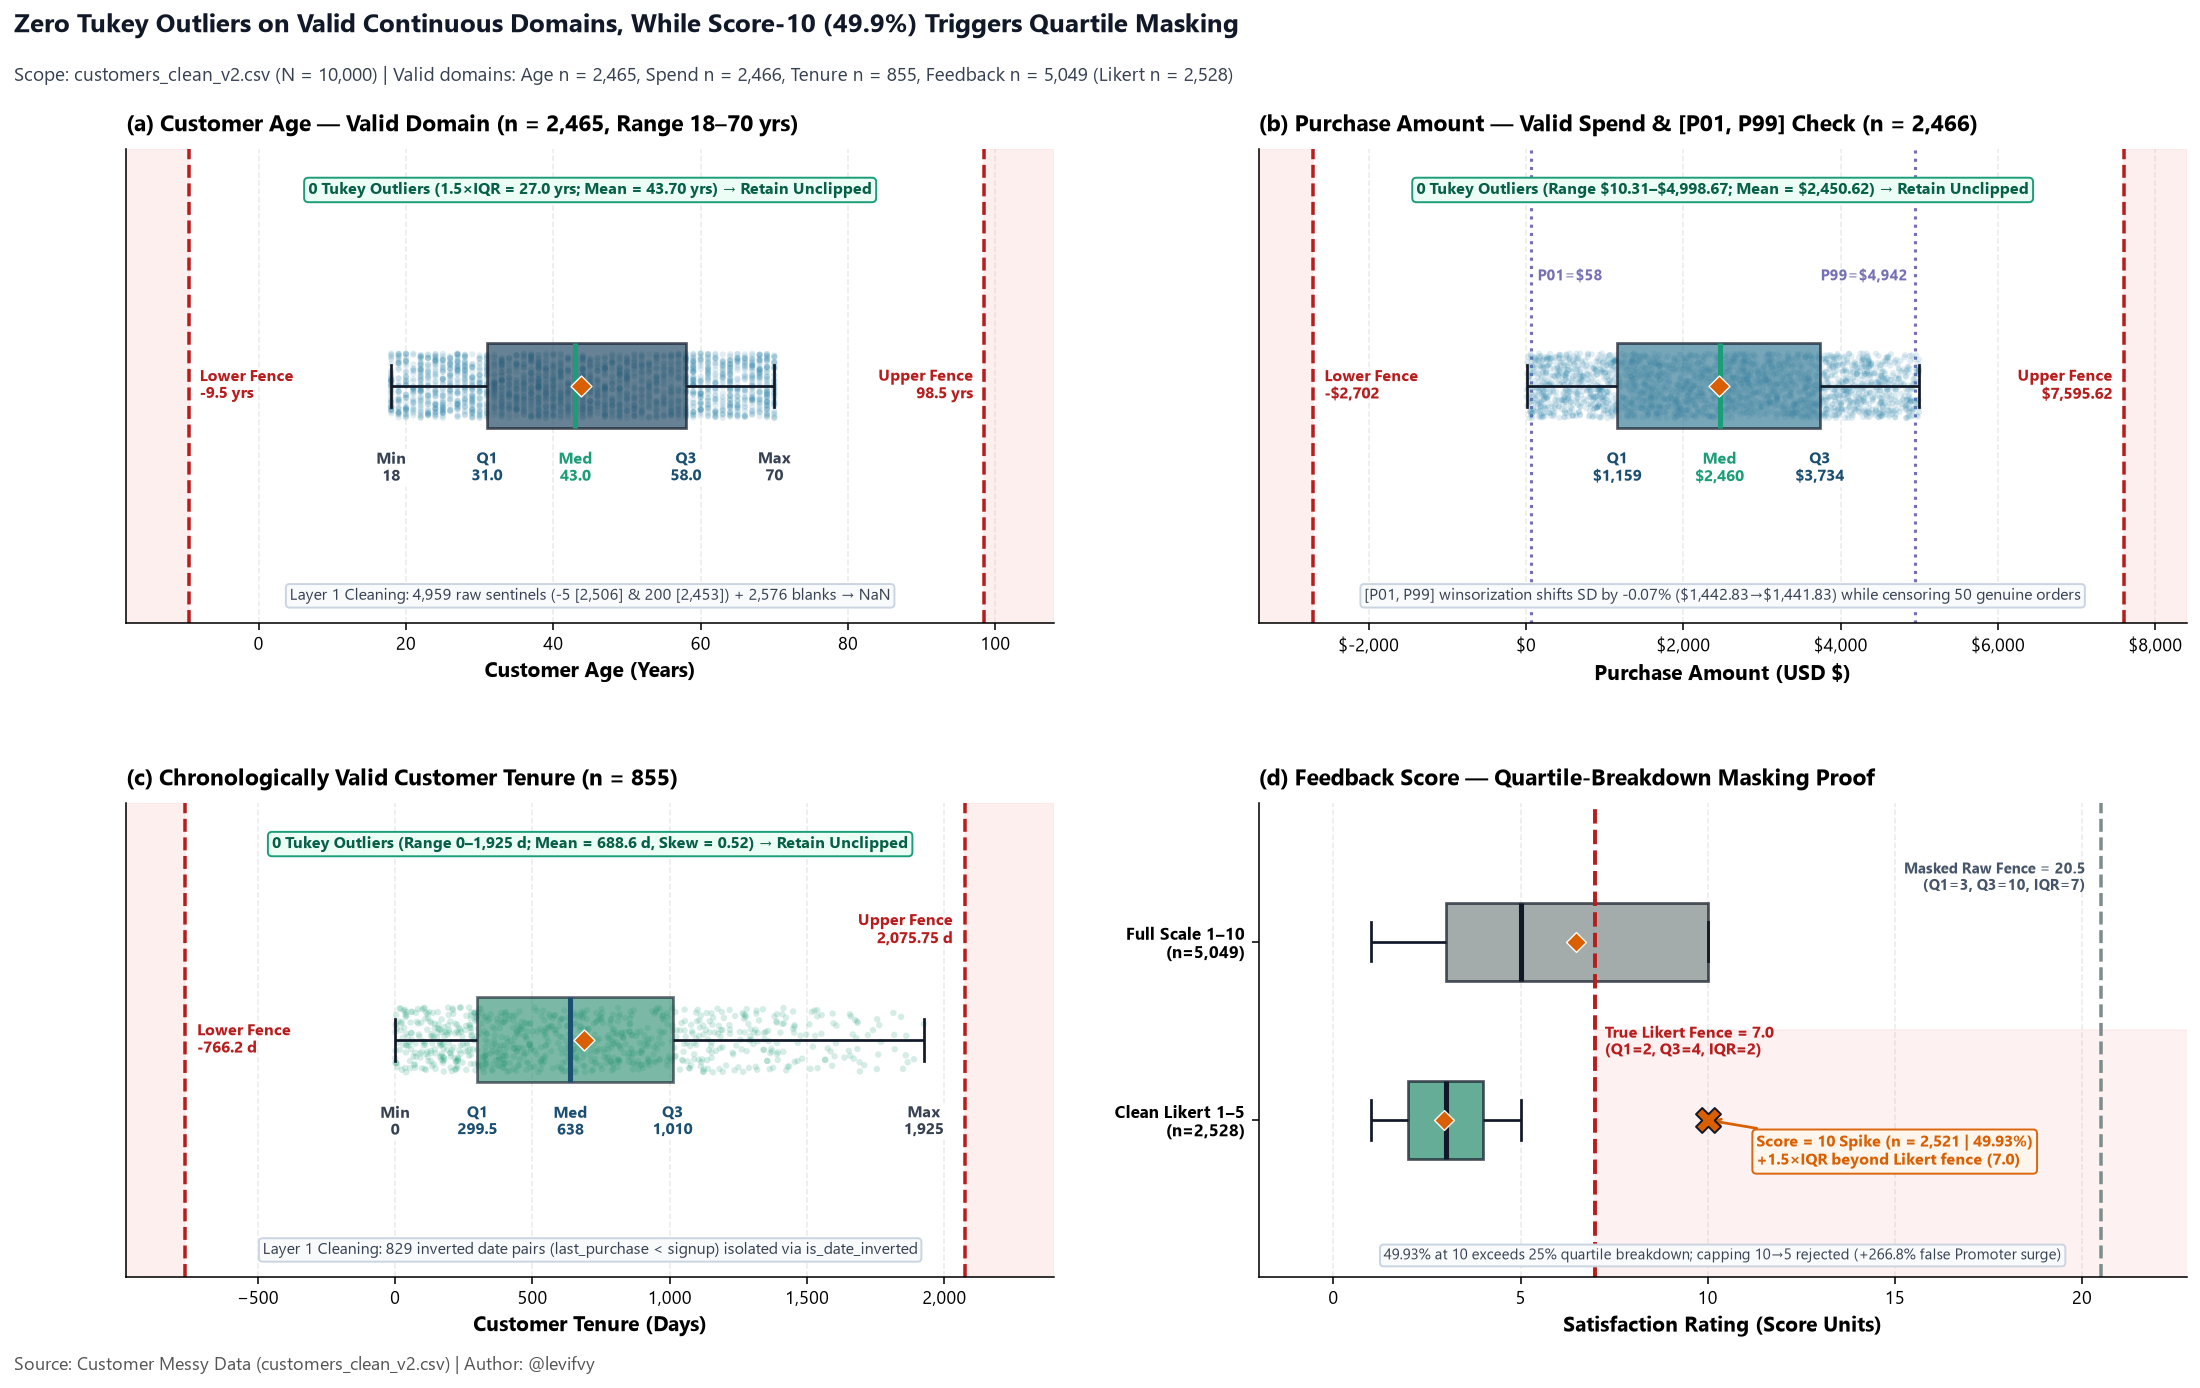

In [19]:
from src.visualization import (
    plot_m2_imputation_variance_distortion,
    plot_m2_iqr_outlier_boxplots,
)

fig_m2_iqr = plot_m2_iqr_outlier_boxplots(df_v2_m2, save=True)
plt.show()
plt.close(fig_m2_iqr)

**Visual Interpretation — Tukey IQR Fences & Quartile-Breakdown Masking (`Q1`, `Q2`, `Q3`):**
- **Panels (a)–(c) — Zero Continuous Domain Outliers (`Q1` Age, `Q2` Spend, `Q3` Tenure):** Once upstream ingestion sentinels (`4,959` rows of `-5`/`200` in `age`, `5,034` rows of `-999`/`'N/A'` in `purchase_amount`, and `829` inverted date pairs in `customer_tenure_days`) are isolated to `NaN`, 100% of observed values sit comfortably inside formal Tukey inner fences (`age` range `18–70` yrs inside `[-9.5, 98.5]`, $n = 2,465$; `purchase_amount` range `$10.31–$4,998.67` inside `[-$2,702.36, $7,595.62]`, $n = 2,466$; `customer_tenure_days` range `0–1,925` days inside `[-766.25, 2,075.75]`, $n = 855$). On `purchase_amount`, `[P01 = $57.52, P99 = $4,941.58]` winsorization lowers `SD` by just `-0.07%` (`$1,442.83 → $1,441.83`) while needlessly censoring `50` genuine orders, confirming **unclipped retention** as optimal.
- **Panel (d) — Quartile Masking of the `feedback_score = 10` Spike (`Q3` Satisfaction):** Across all $n = 5,049$ valid ratings, the `2,521` observations at `score = 10` (`49.93%` of valid) exceed the `25%` breakdown point of sample quartiles, pulling raw `Q3` from `4.0` to `10.0` (`IQR = 7.0`) and pushing the raw upper fence to `20.5` — completely masking the anomaly. Evaluated against the true `1–5` Likert scale (`feedback_score_1_to_5`, $n = 2,528$, `Q1 = 2.0`, `Median = 3.0`, `Q3 = 4.0`, `upper fence = 7.0`), `score = 10` stands `+1.5 × IQR` above the fence. Rather than capping `10 → 5` (which fabricates a `+266.77%` Promoter surge from `945` to `3,466`), isolating the anomaly via `is_score_10_spike` preserves unbiased `1–5` sentiment metrics.

Saved figure: assets/charts/m2_imputation_variance_distortion.png


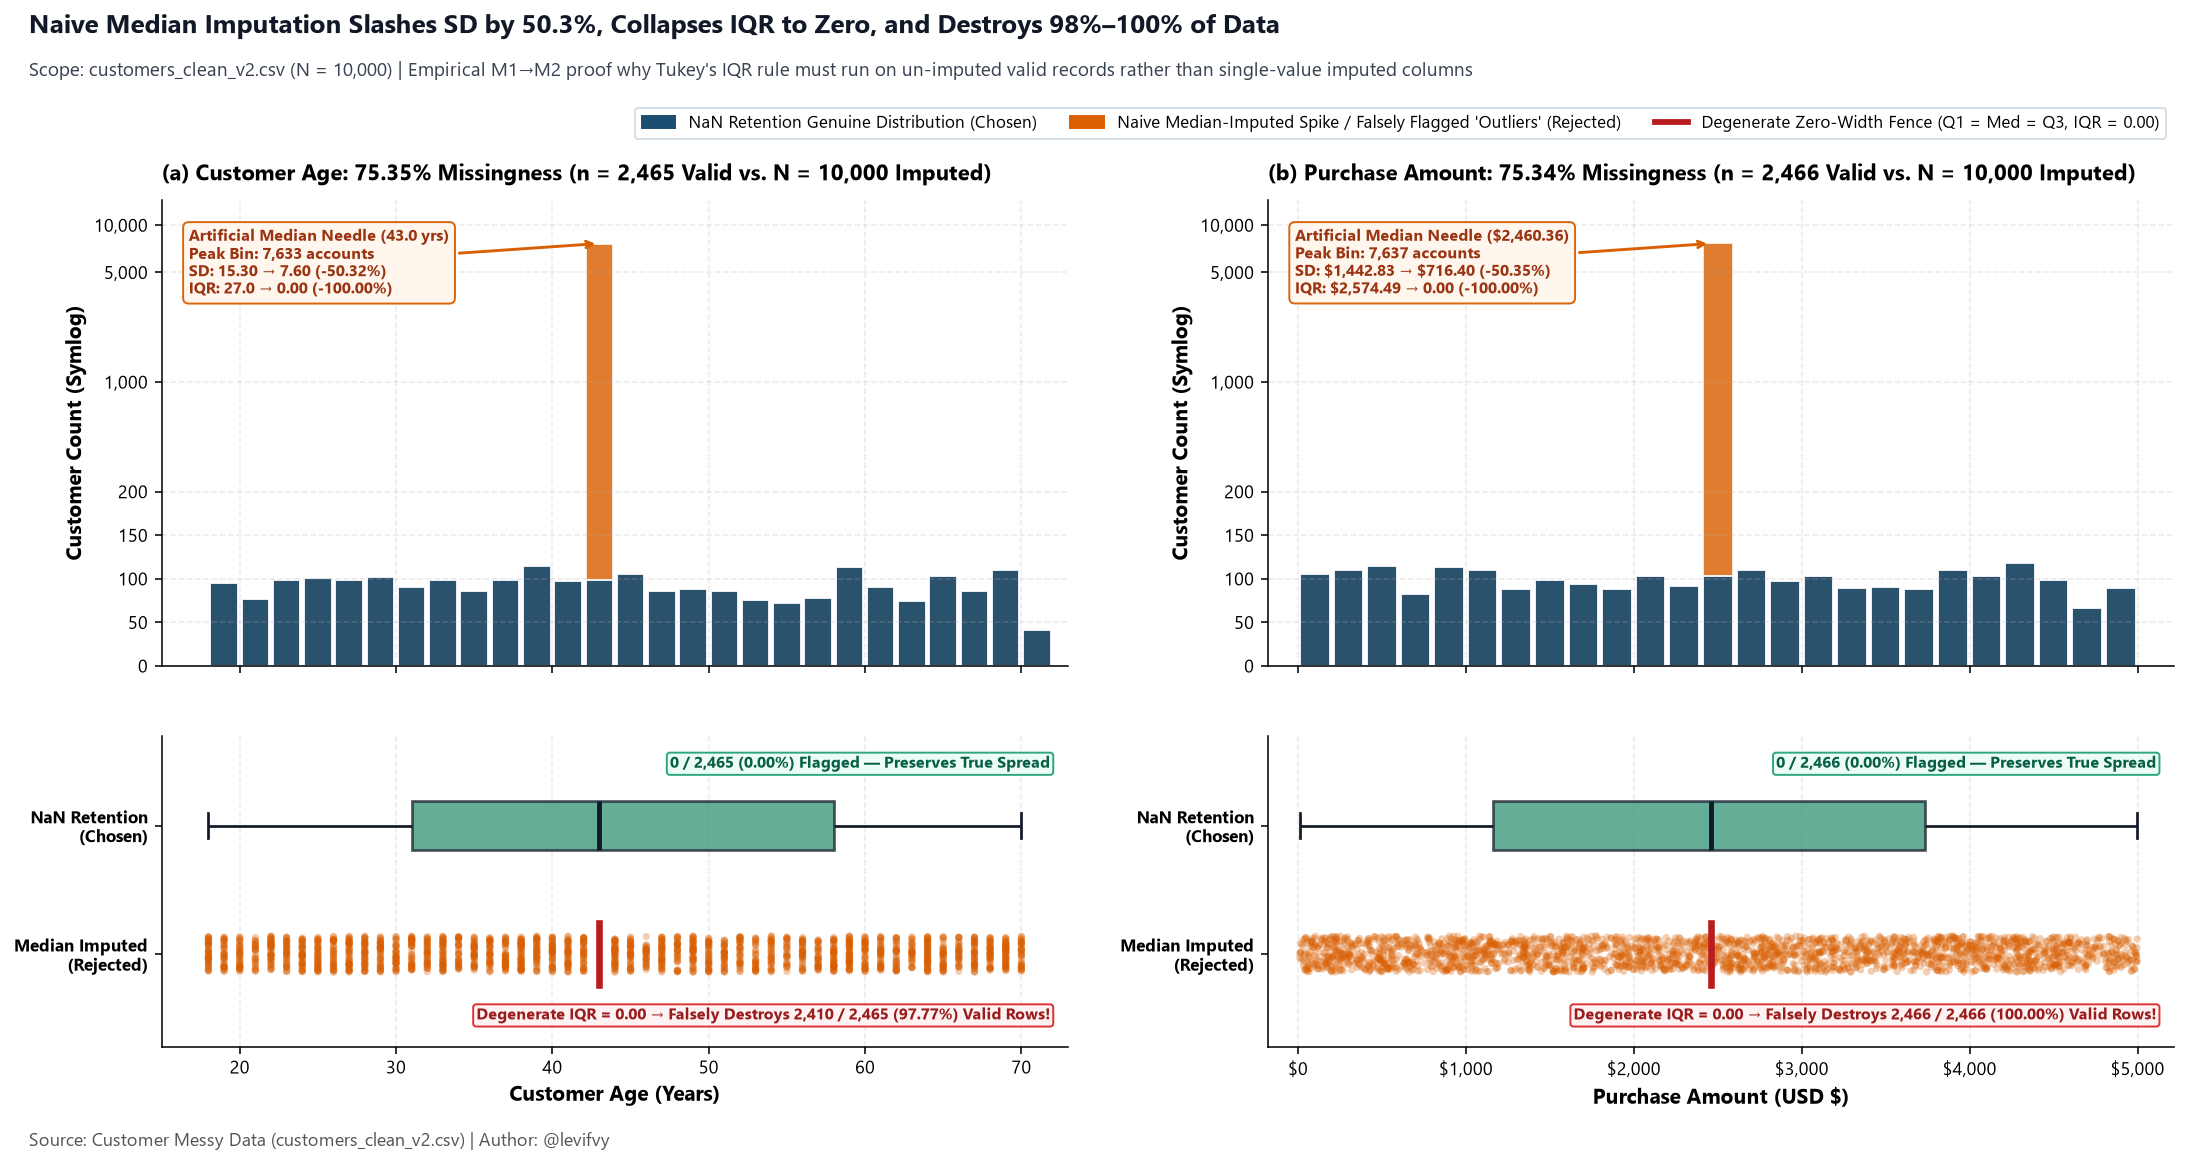

In [20]:
fig_m2_imp = plot_m2_imputation_variance_distortion(df_v2_m2, save=True)
plt.show()
plt.close(fig_m2_imp)

**Visual Interpretation — Why Outlier Filtering Must Precede or Exclude Single Imputation (`Q1`, `Q2`):**
- **Artificial Variance Compression (`M1` Link):** Filling `75.35%` missing `age` ($7,535$ rows at `43.0` yrs) and `75.34%` missing `purchase_amount` ($7,534$ rows at `$2,460.36`) injects a massive needle spike exceeding `7,630` accounts in a single central bin (`symlog` top panels), slashing parametric `SD` by **`-50.32%`** (`15.30 → 7.60` yrs) on `age` and **`-50.35%`** (`$1,442.83 → $716.40`) on `purchase_amount`.
- **Catastrophic IQR & Tukey Fence Collapse (`M2` Link):** Because `>75%` of the imputed column equals the median, `Q1 = Median = Q3` (`IQR = 0.00`, a **`-100.00%`** collapse). Consequently, the $1.5 \times \text{IQR}$ fences degenerate to zero-width points (`[43.0, 43.0]` yrs and `[$2,460.36, $2,460.36]`), **falsely destroying `2,410 / 2,465` (`97.77%`) of genuine customer ages and `2,466 / 2,466` (`100.00%`) of genuine transactions** as supposed "outliers" (`bottom panels`). Retaining `NaN` on primary analytical columns preserves 100% of genuine customer variance (`0.00%` false outlier loss).

---

## 9. `[M3]` Multi-Dimensional Segment Aggregations (`groupby`, `agg` & `pivot_table`)

Univariate (`E4`) and single-factor bivariate (`E5`) summaries can obscure compound operational risks that emerge only at the intersection of **demographics, geography, commercial spend tiers, and CRM reachability**. Using explicit `observed=True` categorical grouping (`src/analysis.py` + `src/features.py`), we construct three multi-dimensional segment matrices:

1. **Demographic × Lifecycle Cohort Matrix (`groupby` + named `.agg()`):** `gender × age_group` (`3 × 5 = 15` cells) pairing raw spend totals with normalized **Revenue per 1,000 Valid Customers (`KPI-3`)**, **Omnichannel Reachability (`KPI-4`)**, and **Profile Completeness (`KPI-1`)**.
2. **Geographic × Age Cohort Spend Matrix (`pd.pivot_table` with margins):** `country × age_group` (`count`, `mean`, `median`, `sum` across `7 × 6` cells including `"All"` margins) auditing sample sizes ($n$) alongside transaction averages.
3. **CRM Reachability × Commercial Spend Tier Matrix (`pivot_table` + `groupby/agg`):** `contact_reachability_tier × spend_tier` (`4 × 4 = 16` cells) crossed with `feedback_tier` sentiment to isolate **unreachable VIP (`High > $3,500`) revenue exposure**.

In [21]:
from src.analysis import (
    build_m3_country_age_pivot,
    build_m3_demographic_spend_groupby,
    build_m3_reachability_spend_tier_pivot,
    load_clean_customers,
)
from src.features import engineer_features

df_enriched_m3 = engineer_features(load_clean_customers("v2"))

m3_demo_groupby = build_m3_demographic_spend_groupby(df_enriched_m3)
m3_country_age_piv = build_m3_country_age_pivot(df_enriched_m3)
m3_reach_spend_piv = build_m3_reachability_spend_tier_pivot(df_enriched_m3)

print("=== [M3.1] DEMOGRAPHIC COHORT AGGREGATION: GENDER x AGE_GROUP (GROUPBY + AGG) ===")
print(m3_demo_groupby.round(2).to_string(index=False))

piv_display_cols = [
    "country",
    "n_age_18_29",
    "n_age_30_44",
    "n_age_45_59",
    "n_age_60_plus",
    "n_age_unknown",
    "n_all_ages",
    "mean_age_18_29",
    "mean_age_30_44",
    "mean_age_45_59",
    "mean_age_60_plus",
    "mean_all_ages",
    "sum_all_ages",
]
print("\n=== [M3.2] COUNTRY x AGE_GROUP SPEND PIVOT TABLE (COUNTS, MEANS & TOTALS) ===")
print(m3_country_age_piv[piv_display_cols].round(2).to_string(index=False))

reach_display_cols = [
    "contact_reachability_tier",
    "spend_tier",
    "account_count",
    "pct_of_spend_tier",
    "verified_revenue_usd",
    "pct_of_total_revenue",
    "mean_spend_usd",
    "promoter_4_5_pct_of_valid_fb",
    "detractor_1_2_pct_of_valid_fb",
]
print("\n=== [M3.3] REACHABILITY TIER x SPEND TIER PIVOT & SENTIMENT EXPOSURE ===")
print(m3_reach_spend_piv[reach_display_cols].round(2).to_string(index=False))

=== [M3.1] DEMOGRAPHIC COHORT AGGREGATION: GENDER x AGE_GROUP (GROUPBY + AGG) ===
 gender            age_group  account_count  account_share_pct  valid_spend_n  spend_coverage_pct  total_spend_usd  mean_spend_usd  std_spend_usd  median_spend_usd  iqr_spend_usd  rev_per_1k_valid_customers_usd  reachable_pct  mean_completeness_score
   Male  18-29 (Young Adult)            206               2.06             45               21.84        108386.40         2408.59        1441.66           2337.39        2615.67                      2408586.67          50.49                     0.64
   Male 30-44 (Early Career)            284               2.84             81               28.52        183866.14         2269.95        1486.28           2256.46        2748.49                      2269952.35          42.25                     0.63
   Male   45-59 (Mid-Senior)            248               2.48             63               25.40        150546.73         2389.63        1394.09           2203.12  

**Quantitative & Strategic Interpretation (`M3`):**
- **Unreachable VIP Revenue Exposure (`Q2`, `Q3`):** Crossing `contact_reachability_tier` with `spend_tier` exposes the dataset's single largest commercial vulnerability: out of **`724` VIP `High (>$3,500)` accounts** (`$3,057,313.93`, or **`50.59%`** of all verified revenue), **`405` VIPs (`55.94%` of all VIPs)** are **`Unreachable (None)`**, locking **`$1,713,463.02` (`28.35%` of total company-wide verified revenue)** outside email and SMS retention workflows. Conversely, only **`58` VIPs (`8.01%`, `$246,953.52` / `4.09%` of revenue)** are reachable via `Omnichannel (Both)`. Worse still, within unreachable VIPs with valid feedback ($n = 201$), **`Detractors (1-2)` (`22.39%`) exceed `Promoters (4-5)` (`15.92%`)**, preventing proactive service recovery on high-value accounts.
- **Small-Cell Volatility vs. Normalized Parity in `gender × age_group` (`Q1`, `Q2`):** While `Unknown` gender × `60+ (Senior)` ($n_{\text{spend}} = 34$) exhibits a sample mean of `$2,950.09` (`$2,950,087.06` per 1k valid customers) vs. `$2,023.41` in `Unknown × 18-29` ($n_{\text{spend}} = 37$), larger known demographic cells (`Male` and `Female` across `18–60+`, $n_{\text{spend}} = 40\text{–}81$) cluster tightly between **`$2,269.95` and `$2,519.28`** (`KPI-3: $2.27M–$2.52M / 1k`), and `75.87%` (`$4,584,783.83`) of verified spend resides in `age_group == 'Unknown'` ($n_{\text{spend}} = 1,866$). Meanwhile, `mean_completeness_score` (`KPI-1`) rises from **`0.4721`** in `Unknown × Unknown` ($n = 1,852$) to **`0.6308–0.6407`** when both `gender` and `age_group` are populated.
- **Cross-Border × Age Spend Granularity (`Q1`, `Q2`):** The `country × age_group` pivot confirms why sample-size reporting ($n$) alongside means is mandatory: known country × known age cells contain only **`14–37` valid orders per cell** (e.g., `USA × 60+` $n = 14$, mean `$2,261.76`; `India × 30-44` $n = 33$, mean `$2,864.99`), whereas `age_unknown` accounts for `283–324` orders per country (`1,866 / 2,466 = 75.67%` overall), reinforcing that apparent cell-level spikes reflect small-sample variance rather than structural market premiums.

---

## 10. `[M4]` Feature Engineering & Analytical Value (`customers_enriched_v1.csv`)

To unlock executive segmentation, lifecycle retention modeling (`M6`), normalized revenue benchmarking (`A1`), and variance-stabilized parametric analysis (`A4`), we implement the six canonical analytical features defined in `specs/ontology.md` §3.2 (`src/features.py`), expanding the `21`-column `v2` schema into the **`27`-column `customers_enriched_v1.csv` dataset**:

| Engineered Feature | Dtype | Exact Ontology Rule (`specs/ontology.md` §3.2) | Analytical Value |
|---|---|---|---|
| `age_group` | ordered `category` | `18-29 (Young Adult)`, `30-44 (Early Career)`, `45-59 (Mid-Senior)`, `60+ (Senior)`, `Unknown` | Demographic cohort profiling without losing the `75.35%` missing-age population (`Q1`, `Q2`). |
| `spend_tier` | ordered `category` | Fixed thresholds: `< $1,200` (`Low`), `$1,200–$3,500` (`Medium`), `> $3,500` (`High`), `Missing` | Isolates commercial VIP revenue concentration independent of sample quantiles (`Q2`). |
| `feedback_tier` | ordered `category` | `Detractor (1-2)`, `Passive (3)`, `Promoter (4-5)`, `Scale-10 Spike (10)`, `Missing` | Separates standard NPS-style sentiment tiers from the `2,521`-row off-scale `10` anomaly (`Q3`). |
| `contact_reachability_tier` | ordered `category` | `Omnichannel (Both)`, `Email Only`, `Phone Only`, `Unreachable (None)` | Routes CRM retention campaigns by verified channel availability (`Q3`). |
| `customer_tenure_days` | `float64` | `(last_purchase_date - signup_date).dt.days` where `~is_date_inverted` (`else NaN`) | Quantifies true active customer lifecycle duration in days, free of `829` inverted timestamps (`Q3`, `M6`). |
| `log_purchase_amount` | `float64` | `np.log1p(purchase_amount).round(6)` | Compresses the `484.8×` dollar range (`$10.31–$4,998.67`) to `[2.43, 8.52]` for elasticity/scale evaluation (`A4`). |

In [22]:
from src.features import (
    engineer_features,
    summarize_engineered_features,
    validate_enriched_customers,
)

df_v2_m4 = load_clean_customers("v2")
df_enriched = engineer_features(df_v2_m4)
validate_enriched_customers(df_enriched)
m4_profile = summarize_engineered_features(df_enriched)

print(f"Enriched dataset shape: {df_enriched.shape[0]:,} rows × {df_enriched.shape[1]} columns")
print("Engineered columns added:", list(df_enriched.columns[21:]))

cat_profile = m4_profile[m4_profile["feature_type"] == "ordered_category"][
    [
        "feature_name",
        "level_or_scope",
        "n_records",
        "pct_of_total",
        "pct_of_known",
        "valid_spend_n",
        "mean_spend_usd",
        "median_spend_usd",
        "total_spend_usd",
        "spend_share_pct",
    ]
]
print("\n=== [M4.1] ORDERED CATEGORICAL ENGINEERED FEATURES PROFILE ===")
print(cat_profile.round(2).to_string(index=False))

cont_profile = m4_profile[m4_profile["feature_type"] == "continuous_float64"][
    [
        "feature_name",
        "n_records",
        "pct_of_total",
        "cont_mean",
        "cont_std",
        "cont_min",
        "cont_q1",
        "cont_median",
        "cont_q3",
        "cont_max",
        "cont_iqr",
        "cont_skewness",
        "cont_kurtosis",
    ]
]
print("\n=== [M4.2] CONTINUOUS ENGINEERED FEATURES PROFILE ===")
print(cont_profile.round(4).to_string(index=False))

Enriched dataset shape: 10,000 rows × 27 columns
Engineered columns added: ['age_group', 'spend_tier', 'feedback_tier', 'contact_reachability_tier', 'customer_tenure_days', 'log_purchase_amount']

=== [M4.1] ORDERED CATEGORICAL ENGINEERED FEATURES PROFILE ===
             feature_name         level_or_scope  n_records  pct_of_total  pct_of_known  valid_spend_n  mean_spend_usd  median_spend_usd  total_spend_usd  spend_share_pct
                age_group    18-29 (Young Adult)        571          5.71         23.16            134         2334.77           2328.78        312858.64             5.18
                age_group   30-44 (Early Career)        742          7.42         30.10            194         2418.87           2550.22        469260.10             7.77
                age_group     45-59 (Mid-Senior)        648          6.48         26.29            155         2433.83           2390.24        377242.91             6.24
                age_group           60+ (Senior)        

**Quantitative Interpretation (`M4`):**
- **VIP Revenue Concentration via `spend_tier` (`Q2`):** Fixed commercial thresholds demonstrate that **`High (>$3,500)` VIP orders** account for **`29.36%` of valid transactions** ($n = 724$; `7.24%` of all `10,000` accounts) yet generate **`$3,057,313.93` — over half (`50.59%`) of all verified revenue** (`mean = $4,222.81`, `median = $4,213.43`). `Medium ($1,200-$3,500)` ($n = 1,105$, `44.81%` of valid orders) contributes **`43.07%`** (`$2,602,998.72`), while `Low (<$1,200)` ($n = 637$, `25.83%` of valid orders) contributes just **`6.34%`** (`$382,905.81`). Because demographic and geographic segments show uniform average spend (`E5`), **`spend_tier` is the primary actionable value discriminator**.
- **Sentiment & Reachability Tiering (`Q3`):** `feedback_tier` cleanly separates `Scale-10 Spike (10)` ($n = 2,521$, `49.93%` of valid ratings; `$1,476,038.15` spend) from standard Likert respondents, where `Detractor (1-2)` ($n = 1,027$, `20.34%` of valid) exceeds `Promoter (4-5)` ($n = 945$, `18.72%`) and `Passive (3)` ($n = 556$, `11.01%`). `contact_reachability_tier` confirms that `Unreachable (None)` ($n = 5,612$, `56.12%`) holds **`56.06%` (`$3,388,004.29`)** of total verified spend, vs. `6.62%` (`$400,214.23`) in `Omnichannel (Both)` ($n = 634$).
- **Lifecycle Duration & Logarithmic Spend Compression (`Q2`, `Q3`):** Valid `customer_tenure_days` ($n = 855$, `8.55%` of total) spans `0–1,925` days with `mean = 688.59` days (`SD = 464.11`) and `median = 638.00` days (`IQR = 710.50`, `Q1 = 299.50`, `Q3 = 1,010.00`, `skewness = +0.5179`). Meanwhile, `log_purchase_amount` ($n = 2,466$) compresses the `484.8×` raw dollar span (`$10.31–$4,998.67`, `SD = $1,442.83`, `skewness = +0.0139`) into `[2.4257, 8.5171]` (`mean = 7.4910`, `SD = 0.9879`, `median = 7.8085`, `IQR = 1.1690`), while empirically introducing left-skewness (`skewness = -1.6273`, `kurtosis = +2.9457`) because raw spend is uniform rather than right-skewed — a key diagnostic benchmark for `[A4]`.

---

## 11. Medium Level Block 1 (`M1–M4`) — Conclusions & Bridge to `M5–M7`

1. **Cleaning decisions are now explicit and evidence-backed (`M1`):** All `12` raw columns are retained, the `C00001`–`C10000` key is rebuilt losslessly, categorical blanks become `'Unknown'`, and continuous gaps stay `NaN` with missingness flags. Single-value imputation was rejected empirically: it cuts `SD` by about `50%` and collapses `IQR` to `0.00` on `age` and `purchase_amount`, while Welch and Mann-Whitney tests ($p > 0.61$) are consistent with MCAR missingness.
2. **There are no statistical outliers to remove after sentinel cleaning (`M2`):** `age` ($n = 2,465$), `purchase_amount` ($n = 2,466$), and `customer_tenure_days` ($n = 855$) have `0` Tukey outliers, so every valid observation is retained unclipped. The `feedback_score = 10` spike (`2,521` rows, `49.93%` of valid ratings) is a scale anomaly hidden by quartile masking; it is isolated with `is_score_10_spike` instead of being capped to `5`.
3. **Commercial risk sits at the intersection of value and reachability (`M3`):** `405` of `724` `High (>$3,500)` customers (`55.94%`) are `Unreachable (None)`, holding `$1,713,463.02` (`28.35%` of verified revenue). Known `country × age_group` cells hold only `14–37` orders each, so cell-level spend differences must be read with their $n$.
4. **Six ontology features are ready for downstream analysis (`M4`):** `customers_enriched_v1.csv` (`10,000 × 27`) adds `age_group`, `spend_tier`, `feedback_tier`, `contact_reachability_tier`, `customer_tenure_days`, and `log_purchase_amount`. `spend_tier` is the strongest value discriminator: `High` orders are `29.36%` of valid transactions but `50.59%` of revenue.

**Next (`M5–M7`):** correlation analysis on the enriched numeric features (without causal claims), temporal evolution of signups and purchases, and the 1–2 page executive report.

---

## 12. `[M5]` Correlation Analysis (`Pearson r` & `Spearman rho`) — Association, Not Causation

Univariate (`E4`) and single-factor bivariate (`E5`) results describe variables one at a time. To test whether the analytical features carry **shared linear or rank signal**, we compute a full correlation matrix in `src/analysis.py` (`compute_correlation_matrices`, `compute_correlation_pairwise_tests`, `compute_correlation_highlights`) and export it to `data/processed/summaries/m5_*.csv`.

**Variable selection (six columns, justified in code):** `age`, `purchase_amount`, `customer_tenure_days`, `feedback_score_1_to_5`, `completeness_score`, and `log_purchase_amount`. Raw `feedback_score` (which mixes `1–5` with the `2,521` off-scale `10` ratings) is deliberately excluded in favour of the clean Likert column; `customer_id`, `name`, and raw dates are excluded because they are identifiers or non-numeric. `log_purchase_amount` is a deterministic `np.log1p` rescaling of `purchase_amount`, so it is reported **only as a collinearity/transformation check** and flagged with `is_monotone_transform = True` in the pairwise table.

**Method:** every coefficient is computed on complete pairwise observations only (`pandas.dropna()` per pair, `scipy.stats.pearsonr`, `scipy.stats.spearmanr`), so the pairwise $n$ is reported for every cell and ranges from `206` to `2,528`. All correlations are **observational associations** — none of the statements below implies that one variable drives another.

In [23]:
from src.analysis import (
    compute_correlation_highlights,
    compute_correlation_matrices,
    compute_correlation_pairwise_tests,
    load_clean_customers,
)
from src.features import engineer_features

df_enriched_m5 = engineer_features(load_clean_customers("v2"))

m5_matrices = compute_correlation_matrices(df_enriched_m5)
m5_tests = compute_correlation_pairwise_tests(df_enriched_m5)
m5_highlights = compute_correlation_highlights(m5_tests)

print("=== [M5.1] PEARSON r CORRELATION MATRIX (pairwise-complete observations) ===")
print(m5_matrices["pearson"].round(4).to_string())

print("\n=== [M5.2] SPEARMAN rho CORRELATION MATRIX ===")
print(m5_matrices["spearman"].round(4).to_string())

print("\n=== [M5.3] PAIRWISE VALID n PER MATRIX CELL ===")
print(m5_matrices["n_pair"].to_string())

print("\n=== [M5.4] TOP 5 INDEPENDENT ASSOCIATIONS (monotone transform excluded) ===")
print(
    m5_highlights[
        [
            "rank",
            "variable_x",
            "variable_y",
            "n_pair",
            "pearson_r",
            "pearson_p",
            "spearman_rho",
            "spearman_p",
            "pearson_strength_label",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print("\n=== [M5.5] MONOTONE-TRANSFORM COLLINEARITY CHECK ===")
print(
    m5_tests.loc[
        m5_tests["is_monotone_transform"],
        ["variable_x", "variable_y", "n_pair", "pearson_r", "spearman_rho"],
    ].to_string(index=False)
)

=== [M5.1] PEARSON r CORRELATION MATRIX (pairwise-complete observations) ===
                          age  purchase_amount  customer_tenure_days  feedback_score_1_to_5  completeness_score  log_purchase_amount
variable                                                                                                                            
age                    1.0000           0.0430                0.1263                -0.0296             -0.0064               0.0362
purchase_amount        0.0430           1.0000               -0.0560                -0.0178             -0.0038               0.8845
customer_tenure_days   0.1263          -0.0560                1.0000                -0.0351              0.0017              -0.0601
feedback_score_1_to_5 -0.0296          -0.0178               -0.0351                 1.0000             -0.0330              -0.0288
completeness_score    -0.0064          -0.0038                0.0017                -0.0330              1.0000              

**Quantitative Interpretation (`M5`):**
- **The matrix is dominated by near-zero coefficients (`Q2`, `Q3`):** across the `14` independent variable pairs in `data/processed/summaries/m5_correlation_pairwise_tests.csv`, the largest association is only **`|r| = 0.1263` / `|rho| = 0.1216`** for `age` × `customer_tenure_days` ($n = 206$; $p = 0.0704$ / $0.0817$), i.e. roughly **`1.6%` shared variance** ($r^2 = 0.0159$). **No independent pair reaches $p < 0.05$**; the smallest p-value is $p = 0.0662$ for `feedback_score_1_to_5` × `completeness_score` ($\rho = -0.0365$, $n = 2{,}528$).
- **Spend is statistically indistinguishable from independent of every other analytical variable (`Q2`):** `purchase_amount` versus `age` ($r = 0.0430$, $p = 0.2930$, $n = 600$), `customer_tenure_days` ($r = -0.0560$, $p = 0.4098$, $n = 219$), `feedback_score_1_to_5` ($r = -0.0178$, $p = 0.6508$, $n = 648$), and `completeness_score` ($r = -0.0038$, $p = 0.8504$, $n = 2{,}466$). This is the multivariate counterpart of the `E5` result that segment mean spend is homogeneous: within this dataset, transaction value varies almost entirely on its own rather than jointly with demographics, lifecycle, satisfaction, or record completeness.
- **The only strong coefficient is a transformation artefact (`Q2`):** `purchase_amount` × `log_purchase_amount` reports $r = 0.8845$ and $\rho = 1.0000$ across $n = 2{,}466$ valid orders, flagged `is_monotone_transform = True` in `m5_correlation_pairwise_tests.csv` and excluded from `m5_correlation_highlights.csv`. The perfect Spearman rank identity proves the two columns carry the same ordering (they must never enter the same model, `A4`), while $r < 1$ quantifies the curvature the `log1p` transform introduces.
- **Sample-size caveat, always reported:** coverage of the underlying attributes is uneven, so pairwise $n$ ranges from **`206`** (`age` × `customer_tenure_days`, the intersection of `24.65%` age and `8.55%` tenure coverage) to **`2,528`** (`feedback_score_1_to_5` × `completeness_score`), as recorded in `m5_correlation_pairwise_n.csv`. The diagonal of that table holds univariate valid counts (`completeness_score = 10,000`) and must not be read as pair overlap. Correlations are associations only; no causal interpretation is warranted.

Saved figure: assets/charts/m5_correlation_heatmap.png


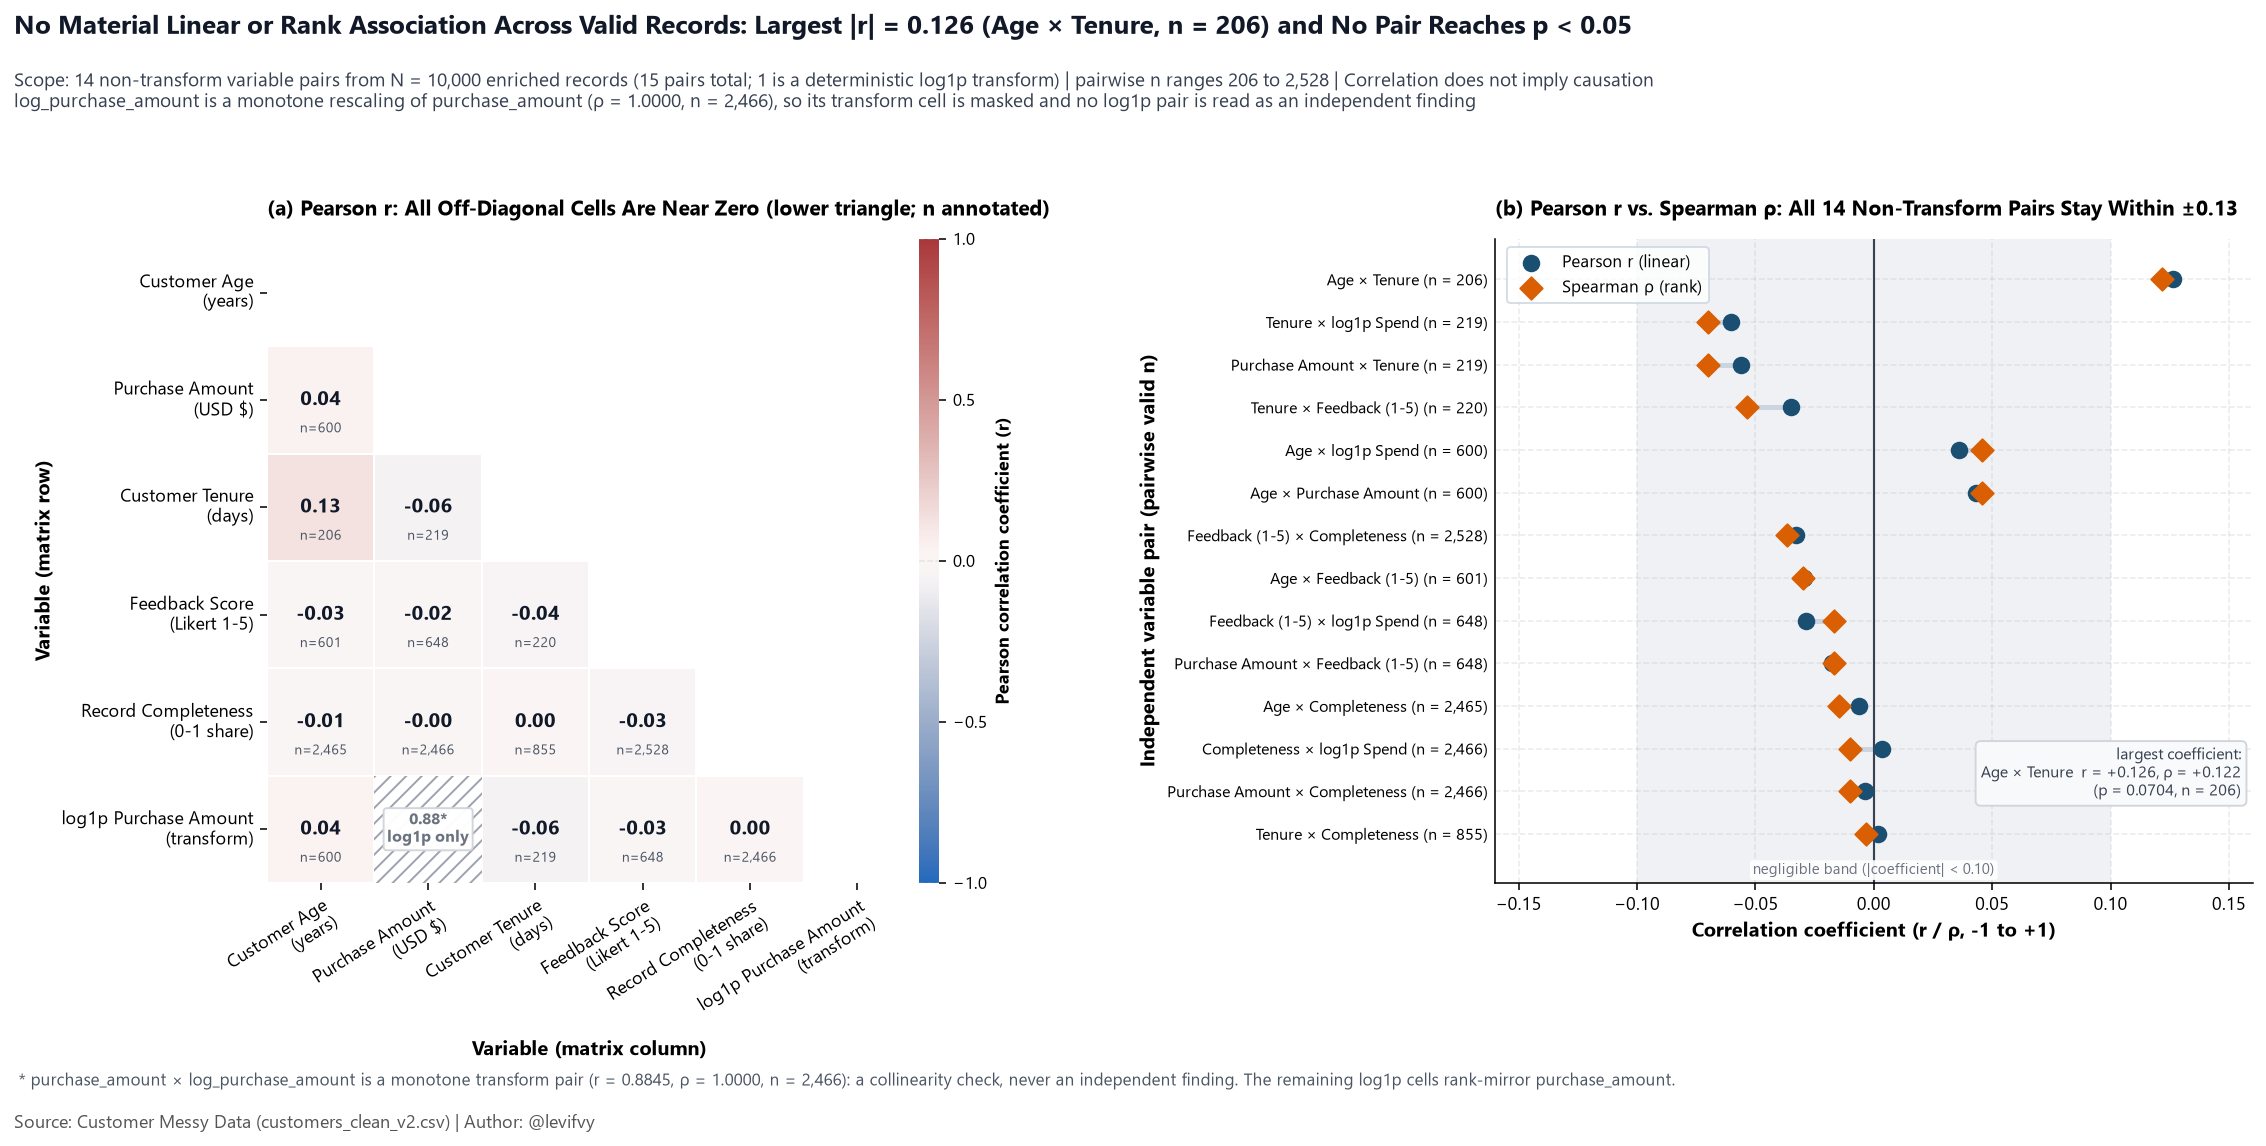

In [24]:
from src.visualization import plot_m5_correlation_heatmap

fig_m5_heatmap = plot_m5_correlation_heatmap(df_enriched_m5)

#### Visual interpretation — `assets/charts/m5_correlation_heatmap.png`

The lower-triangle Pearson heatmap (panel a) paints almost the whole matrix in the neutral centre of the `vlag` scale: every off-diagonal cell sits between `|r| = 0.0017` and `|r| = 0.1263`, and the strongest cell (`Customer Age` × `Customer Tenure`, `r = 0.13`, `n = 206`) is only just visible. Each cell prints its own pairwise `n`, which spans `206` (Age × Tenure) to `2,528` (Feedback × Completeness), so no coefficient is read without its sample size. The single `purchase_amount` × `log_purchase_amount` cell is hatched and labelled "log1p only" (`r = 0.8845`, `ρ = 1.0000`, `n = 2,466`) and is explicitly excluded from the narrative: it is a deterministic rescaling of the same variable, not an association. The `1.00` diagonal cells are masked so they cannot be mistaken for findings.

The companion dumbbell panel (b) plots Pearson `r` (circles) and Spearman `ρ` (diamonds) for the `14` non-transform pairs, sorted by strength. All fourteen markers fall inside or immediately beside the shaded "negligible" band (`|coefficient| < 0.10`); the maximum is `r = +0.126` / `ρ = +0.122` (Age × Tenure, `n = 206`, `p = 0.0704` / `0.0817`) and the smallest p-value in the whole matrix is `0.0662` (Feedback × Completeness, `n = 2,528`). Nothing reaches `α = 0.05`.

**Business reading:** this is the multivariate confirmation of `E5`, answering `Q2` and `Q3`. Spend (`purchase_amount`) is not linearly or monotonically associated with age (`r = 0.0430`, `n = 600`), tenure (`r = -0.0560`, `n = 219`), satisfaction (`r = -0.0178`, `n = 648`) or record completeness (`r = -0.0038`, `n = 2,466`) — all `p ≥ 0.2930` — so revenue must be modelled and targeted on its own, never inferred from demographic, lifecycle or satisfaction proxies. The chart states "correlation does not imply causation" because no coefficient here licenses either direction of a causal claim; the near-zero coefficients mean *no detectable linear/rank signal at this n*, not proven independence.

---

## 13. `[M6]` Temporal & Cohort Evolution (Signup Cohorts and Last-Purchase Activity)

The cleaned dataset contains two independent date fields with heavy missingness, so every temporal statement must start from an explicit **coverage and exclusion audit**. `build_m6_date_coverage_audit` (`src/analysis.py`) reports, per metric, the numerator, denominator, share, and exclusion rule; the series builders (`build_m6_signup_cohorts_monthly`, `build_m6_last_purchase_monthly`, `build_m6_cohort_evolution_summary`, `build_m6_signup_quarter_evolution`) then produce four ordered `m6_*.csv` tables, and `compute_m6_trend_tests` tests each series for a monotone trend with a Spearman rank correlation against the time index.

**Date-integrity rule (explicit, and quantitatively defended):** `signup_date` and `last_purchase_date` are each valid standing alone, so the `829` `is_date_inverted` rows are **retained in the single-date signup and last-purchase series** and excluded only where the two dates are combined (`customer_tenure_days`, `KPI-5`). Dropping them from the single-date series would discard disproportionately late signups (`4,996 → 4,167`) and early last purchases (`3,348 → 2,519`) and manufacture trends; that counterfactual is exported as two rejected sensitivity rows in `m6_trend_tests.csv`. All `NaT` dates are excluded everywhere and pairwise/period $n$ is printed for every series.

In [25]:
from src.analysis import (
    build_m6_cohort_evolution_summary,
    build_m6_date_coverage_audit,
    build_m6_last_purchase_monthly,
    build_m6_signup_cohorts_monthly,
    build_m6_signup_quarter_evolution,
    compute_m6_trend_tests,
    load_clean_customers,
)
from src.features import engineer_features

df_enriched_m6 = engineer_features(load_clean_customers("v2"))

m6_coverage = build_m6_date_coverage_audit(df_enriched_m6)
m6_signup_monthly = build_m6_signup_cohorts_monthly(df_enriched_m6)
m6_activity_monthly = build_m6_last_purchase_monthly(df_enriched_m6)
m6_cohorts = build_m6_cohort_evolution_summary(df_enriched_m6)
m6_quarters = build_m6_signup_quarter_evolution(df_enriched_m6)
m6_trends = compute_m6_trend_tests(df_enriched_m6)

print("=== [M6.1] TEMPORAL COVERAGE & DATE-EXCLUSION AUDIT ===")
print(m6_coverage[["metric", "n", "base_n", "pct_of_base"]].to_string(index=False))

signup_cols = [
    "cohort_month",
    "n_signups",
    "n_valid_spend",
    "mean_spend_usd",
    "n_valid_tenure",
    "mean_tenure_days",
    "reachable_pct",
]
print("\n=== [M6.2] MONTHLY SIGNUP COHORTS — FIRST & LAST 6 OF 66 MONTHS ===")
print(pd.concat([m6_signup_monthly[signup_cols].head(6), m6_signup_monthly[signup_cols].tail(6)]).to_string(index=False))

activity_cols = [
    "activity_month",
    "n_purchases",
    "n_valid_spend",
    "mean_spend_usd",
    "median_spend_usd",
    "reachable_pct",
]
print("\n=== [M6.3] MONTHLY LAST-PURCHASE ACTIVITY — FIRST & LAST 6 OF 66 MONTHS ===")
print(pd.concat([m6_activity_monthly[activity_cols].head(6), m6_activity_monthly[activity_cols].tail(6)]).to_string(index=False))

cohort_cols = [
    "signup_year",
    "is_partial_year",
    "n_signups",
    "n_valid_spend",
    "mean_spend_usd",
    "n_valid_tenure",
    "mean_tenure_days",
    "mean_observation_window_days",
    "tenure_to_window_ratio",
    "reachable_pct",
    "mean_feedback_1_to_5",
    "mean_completeness_score",
]
print("\n=== [M6.4] ORDERED SIGNUP-YEAR COHORT EVOLUTION ===")
print(m6_cohorts[cohort_cols].round(4).to_string(index=False))

print("\n=== [M6.5] TREND TESTS (Spearman rho vs. time index; sensitivity rows rejected) ===")
print(
    m6_trends[
        [
            "series",
            "grain",
            "n_points",
            "spearman_rho_vs_time_index",
            "p_value",
            "trend_label",
            "is_sensitivity_check",
        ]
    ].to_string(index=False)
)

print(f"\nQuarterly grain rows: {len(m6_quarters)} | signups covered: {m6_quarters['n_signups'].sum():,}")

=== [M6.1] TEMPORAL COVERAGE & DATE-EXCLUSION AUDIT ===
                                     metric     n  base_n  pct_of_base
                            total_customers 10000   10000     100.0000
                          signup_date_valid  4996   10000      49.9600
                    signup_date_missing_nat  5004   10000      50.0400
                   last_purchase_date_valid  3348   10000      33.4800
             last_purchase_date_missing_nat  6652   10000      66.5200
                           both_dates_valid  1684   10000      16.8400
                      is_date_inverted_true   829    1684      49.2280
           chronologically_valid_dual_dates   855    1684      50.7720
                 customer_tenure_days_valid   855   10000       8.5500
     customer_tenure_days_excluded_inverted   829   10000       8.2900
customer_tenure_days_excluded_missing_dates  8316   10000      83.1600
           signup_rows_if_inverted_excluded  4167    4996      83.4067
    last_purchase_row

**Quantitative Interpretation (`M6`):**
- **Coverage is the dominant limitation and is now explicit (`Q3`):** of the `10,000` accounts, only **`4,996` (`49.96%`)** have a valid `signup_date`, **`3,348` (`33.48%`)** a valid `last_purchase_date`, and **`1,684` (`16.84%`)** both; **`829` of the `1,684` dual-date rows (`49.23%`)** are `is_date_inverted`, leaving **`855` (`50.77%` of dual dates, `8.55%` of all accounts)** chronologically valid tenures (`data/processed/summaries/m6_date_coverage_audit.csv`).
- **Acquisition and recency are flat, not trending (`Q2`, `Q3`):** across all **`66`** calendar months (`2020-08` to `2026-01`), monthly signups range **`57–106`** (mean **`75.70`**; $n = 4{,}996$ dated signups) with $\rho = +0.0609$ ($p = 0.6271$), and monthly last-purchase activity ranges **`36–69`** (mean **`50.73`**; $n = 3{,}348$) with $\rho = +0.0520$ ($p = 0.6785$) in `m6_signup_cohorts_monthly.csv` / `m6_last_purchase_monthly.csv` / `m6_trend_tests.csv`. Signup volume per full year stays within **`887–946`** accounts (`2021–2025`) in `m6_cohort_evolution_summary.csv`.
- **Spend level shows no temporal drift (`Q2`):** monthly mean spend oscillates between **`$1,131.28` and `$3,570.71`** on only **`5–24`** valid orders per activity month ($\rho = -0.0464$, $p = 0.7111$), and the quarterly series over **`23`** quarters is equally trend-free ($\rho = +0.0346$, $p = 0.8755$). Cohort mean spend sits in a tight band of **`$2,239.02–$2,545.73`** across `2020–2025` cohorts ($n = 87$ to $232$ valid orders each).
- **The apparent tenure collapse is right-censoring, not retention decay (`Q3`):** mean `customer_tenure_days` falls monotonically from **`920.27` days** (`2020` cohort, $n = 124$) to **`127.05` days** (`2025` cohort, $n = 41$; $\rho = -1.0000$, $p < 0.000001$), yet the mean observation window `max(last_purchase_date) − mean(signup_date)` shrinks in lockstep from **`1,920` to `207` days**, so the observed-to-window ratio stays between **`0.4793` and `0.6138`** (`m6_cohort_evolution_summary.csv`). Shorter tenures for recent cohorts are therefore an artefact of a shorter observable window; they are not evidence that newer customers churn faster.
- **Quality and reachability profiles are stable across cohorts (`Q1`, `Q3`):** cohort `reachable_pct` stays within **`43.09%–45.78%`**, `mean_feedback_1_to_5` within **`2.8719–3.0651`**, and `mean_completeness_score` within **`0.5904–0.6043`** across the `2020–2025` signup years, so no cohort shows a material shift in contactability, satisfaction, or record quality.

Saved figure: assets/charts/m6_signup_and_activity_trends.png


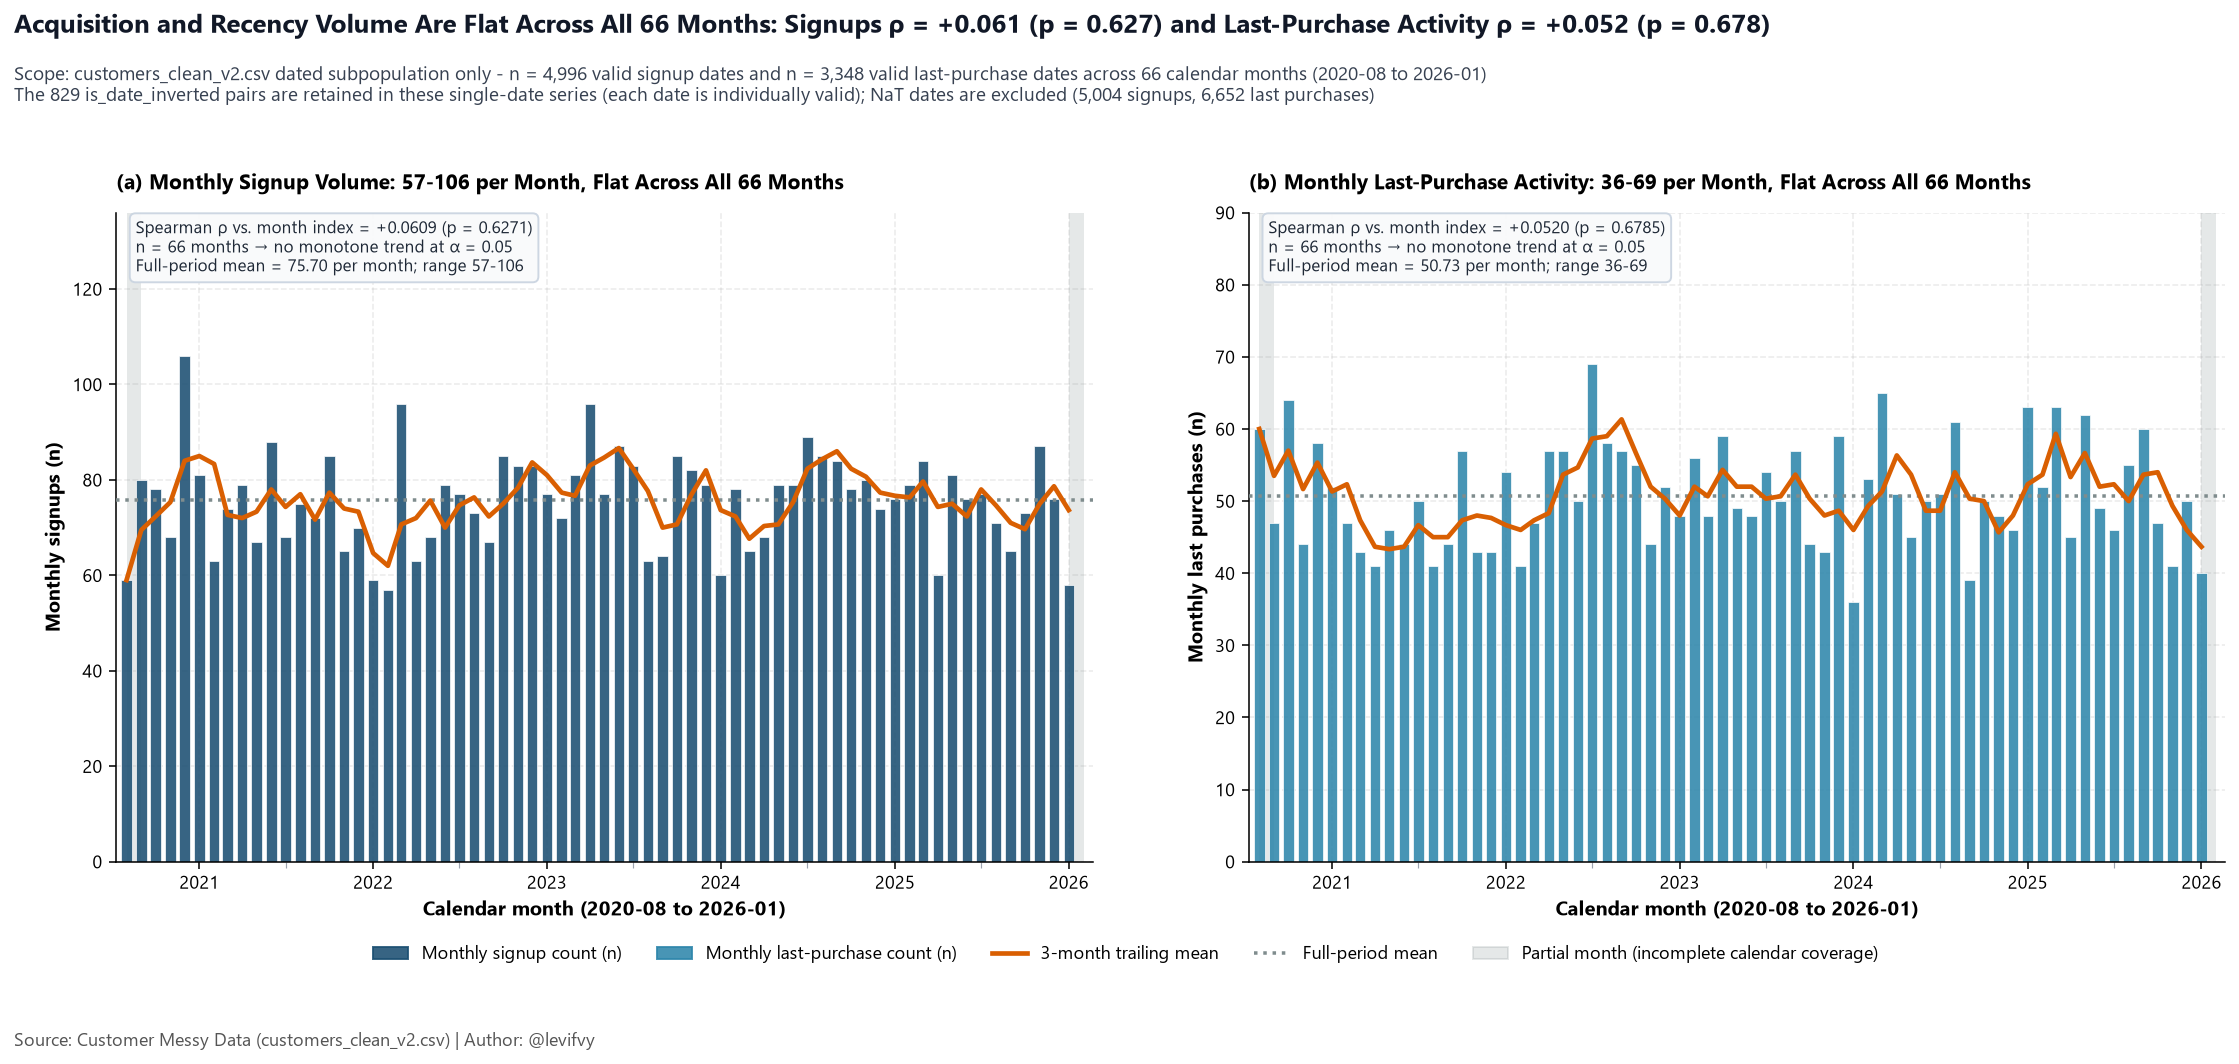

In [26]:
from src.visualization import plot_m6_signup_and_activity_trends

fig_m6_trends = plot_m6_signup_and_activity_trends(df_enriched_m6)

#### Visual interpretation — `assets/charts/m6_signup_and_activity_trends.png`

Panel (a) shows the `66` monthly signup cohorts (`2020-08` to `2026-01`): monthly volume oscillates between `57` and `106` accounts around a full-period mean of `75.70`, and the orange 3-month trailing mean is a flat ribbon with no slope. The Spearman test against the month index gives `ρ = +0.0609` (`p = 0.6271`), so acquisition volume is *trend-free* within the `n = 4,996` dated signups. Panel (b) repeats the exercise for transaction recency: monthly last-purchase activity stays between `36` and `69` (`mean = 50.73`) with `ρ = +0.0520` (`p = 0.6785`) across the `n = 3,348` dated last purchases. The light grey columns at both edges flag the two partial months (`2020-08` starts on the 6th, `2026-01` ends on the 26th), and the subtitle states the date-integrity rule: the `829` `is_date_inverted` rows are **retained** in these single-date series because each date is individually valid, while `NaT` dates are excluded (`5,004` signups, `6,652` last purchases).

**Business reading (`Q2`, `Q3`):** acquisition and recency are stable, so there is no organic growth or collapse to explain and no seasonal spike to exploit — revenue variation must come from order value and segment mix (see `M5`), not from volume drift. The explicit retention rule matters because the rejected sensitivity check in `m6_trend_tests.csv` shows that dropping the `829` inverted pairs would manufacture `ρ = -0.6079` (signups) and `ρ = +0.7664` (activity) — a spurious trend that the chart deliberately avoids.

Saved figure: assets/charts/m6_cohort_tenure_censoring.png


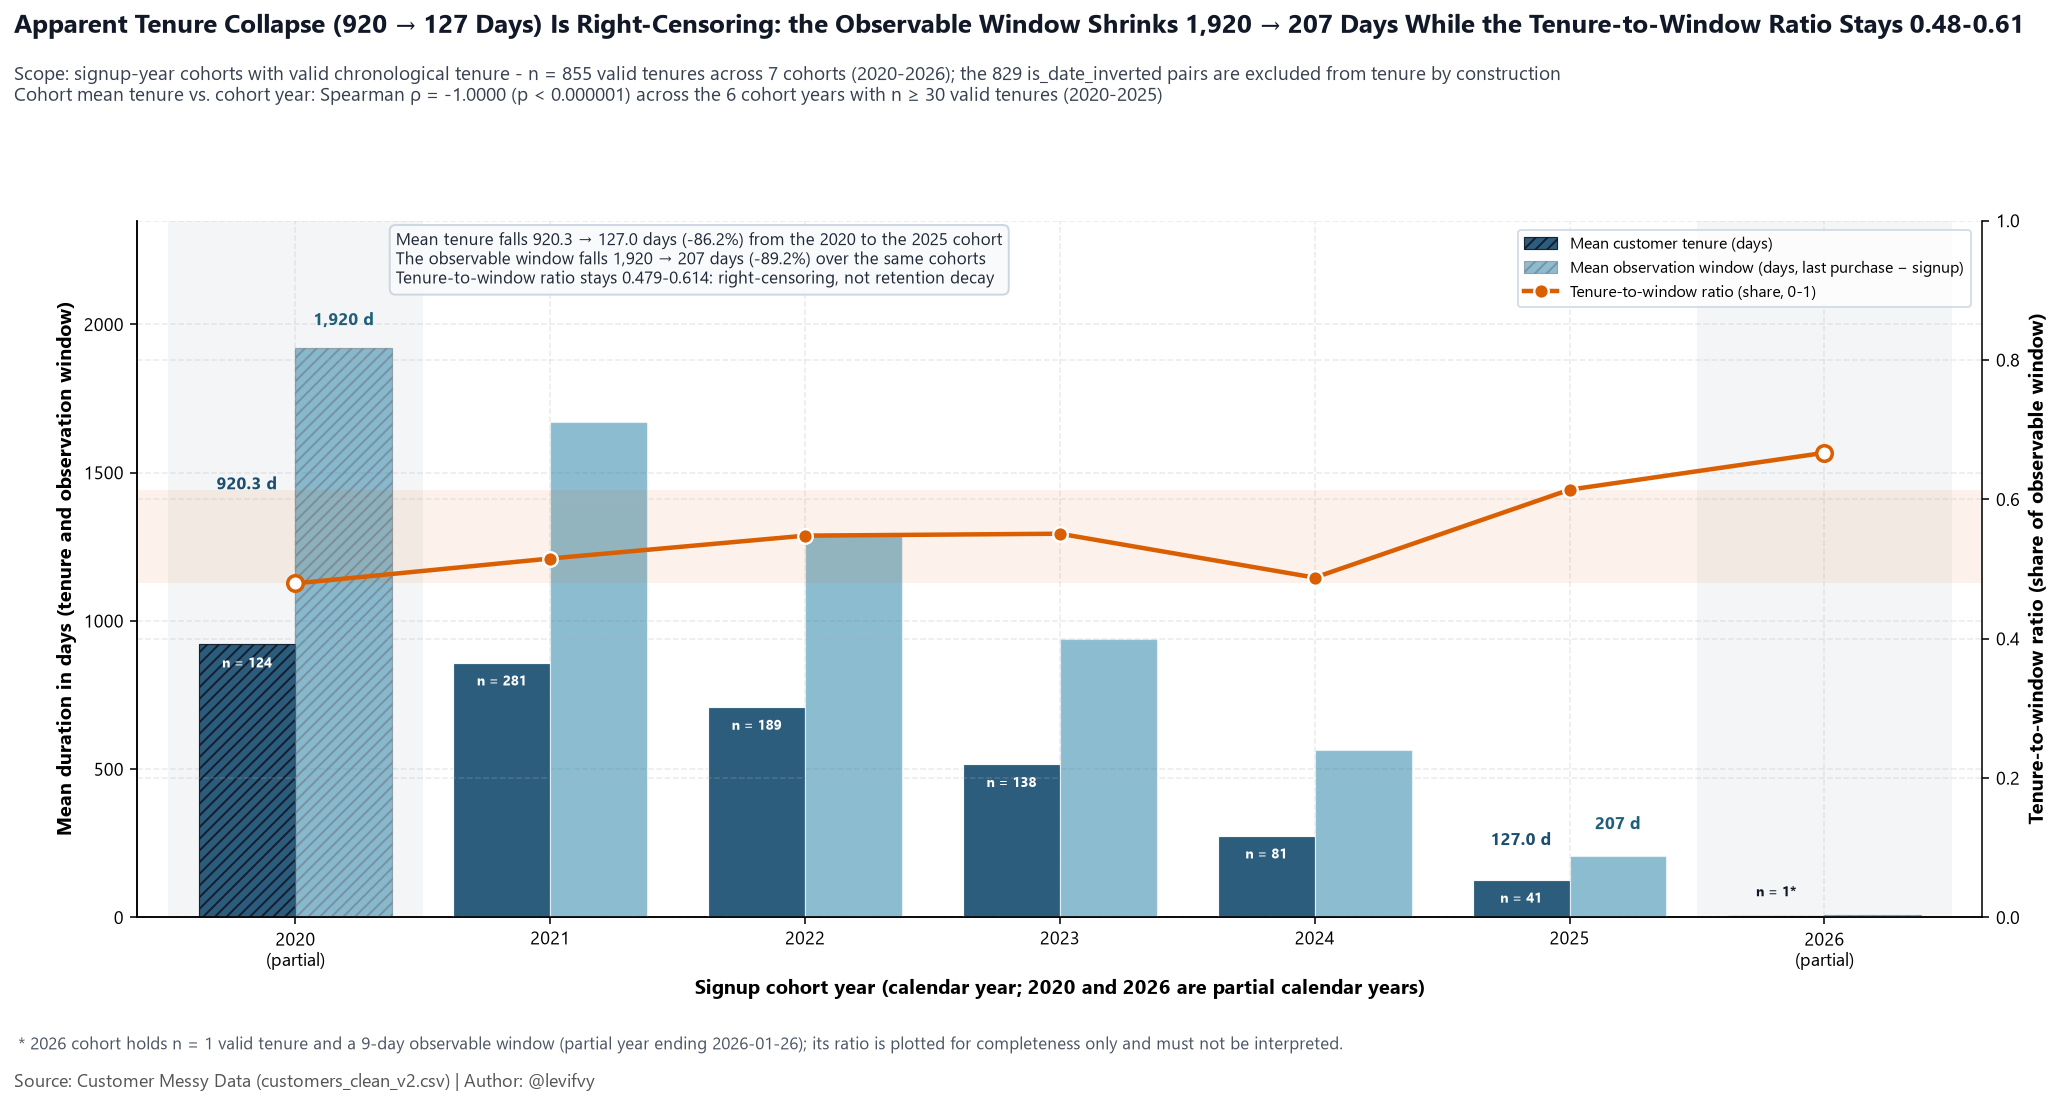

In [27]:
from src.visualization import plot_m6_cohort_tenure_censoring

fig_m6_censoring = plot_m6_cohort_tenure_censoring(df_enriched_m6)

#### Visual interpretation — `assets/charts/m6_cohort_tenure_censoring.png`

The navy bars (mean `customer_tenure_days`) fall monotonically from `920.3` days for the `2020` cohort (`n = 124` valid tenures) to `127.0` days for `2025` (`n = 41`), a `-86.2%` drop that would look like a retention collapse in isolation. The steel-blue bars show why it is not: the mean observation window `max(last_purchase_date) − mean(signup_date)` shrinks in the same direction, from `1,920` to `207` days (`-89.2%`), because recent cohorts have simply had less calendar time in which a last purchase could occur. The orange secondary axis makes the point quantitatively — the tenure-to-window ratio stays inside `0.479`–`0.614` across the six full-detail cohorts (shaded band) and the line is flat, so equal *shares* of the observable window convert to purchases every year. The `2020` and `2026` cohorts are hatched and labelled "partial" (data starts `2020-08-06`, ends `2026-01-26`), and the `2026` cohort carries `n = 1` valid tenure, so its `0.667` ratio is plotted but flagged non-interpretable.

**Business reading (`Q3`):** the apparent tenure decline is right-censoring, not retention decay — `ρ = -1.0000` (`p < 0.000001`) across the six ordered cohort years reflects the observation window, which is not a behavioural metric. Any churn claim built on cohort tenure alone would be an artefact; retention must be measured on cohorts observed for comparable windows. The `829` `is_date_inverted` pairs are excluded from tenure by construction (`n = 855` valid tenures of `10,000` accounts), so all cohort means describe the `8.55%` of accounts with two chronologically valid dates.

---

## 14. `[M7]` Executive Report

The full 1–2 page CEO report is in [`reports/executive_report.md`](../reports/executive_report.md). Every figure in it traces to a `data/processed/summaries/*.csv` table or an analyst handoff (see its Evidence Map). It has five parts: Bottom Line, Data We Could Trust, Findings by Question (`Q1`–`Q3`, one chart each), Recommendations and Limitations.

**Bottom line:**
- **Revenue is concentrated:** 724 High-tier orders (> $3,500; 29.4% of n = 2,466 verified orders) hold $3,057,314, or 50.6% of $6,043,218 verified spend (`KPI-2`, `m4_engineered_features_summary.csv`).
- **Reachability is the main constraint:** 5,612 accounts (56.1%) have no valid email or phone and hold $3,388,004 (56.1%) of verified revenue, including 405 of the 724 High-tier customers ($1,713,463) (`KPI-4`, `m3_pivot_reachability_spend_tier.csv`).
- **Demographic targeting has no support in this data:** spend does not differ by gender, country, city or age group (ANOVA, all p ≥ 0.4752), and none of the 14 independent correlation pairs is significant (max |r| = 0.13, n = 206; smallest p = 0.0662) (`e5_bivariate_hypothesis_tests.csv`, `m5_correlation_pairwise_tests.csv`).

**How to read it (`M7` caveats):** age and spend are valid for about 24.7% of accounts, valid tenure for 8.6% (n = 855). The drop in cohort tenure from 920.3 days (2020) to 127.0 days (2025) is right-censoring, because newer customers have been observed for less time. It is not evidence of churn. All results are observational associations, not causes. Supporting charts: `assets/charts/e4_univariate_demographics_counts.png`, `assets/charts/e5_bivariate_spend_by_demographics.png`, `assets/charts/m6_cohort_tenure_censoring.png`, `assets/charts/m5_correlation_heatmap.png`, `assets/charts/m6_signup_and_activity_trends.png`.

---

## 15. Medium Level (`M1–M7`) — Conclusions & Bridge to Advanced (`A1–A7`)

1. **No detectable linear or rank association (`M5`):** across the 14 independent variable pairs the largest coefficient is |r| = 0.13 (n = 206) and none is significant (smallest p = 0.0662). At these sample sizes only associations near |r| = 0.2 are detectable, so this means "no detectable signal", not proven independence, and no causal reading is made.
2. **Flat acquisition, censored tenure (`M6`):** monthly signups stay flat (no significant trend, p = 0.6271). The fall in cohort mean tenure (920.3 days for 2020 → 127.0 days for 2025) tracks the shrinking observation window, so it is right-censoring, not evidence of churn.
3. **Executive report delivered (`M7`):** [`reports/executive_report.md`](../reports/executive_report.md) turns these results into six recommendations. The two main levers are protecting the High-tier orders (50.6% of verified revenue) and making the 56.1% of unreachable accounts reachable again.
4. **Bridge to Advanced:** `A1` normalises KPIs per 1,000 customers, `A2` adds a city-to-country lookup to replace the corrupted country field, `A3` audits the inverted dates and the off-scale `10` ratings, and `A4` tests a justified transformation of `purchase_amount`.
